In [1]:
!pip install -q "diffusers==0.30.3" scikit-learn seaborn

In [ ]:
from pathlib import Path
import os

# Run this notebook once per category. Set CATEGORY to "bottle" or "capsule".
CATEGORY = "capsule"

if Path("/kaggle/input").exists():
    DATA_ROOT = Path("/kaggle/input")
    DEFAULT_NORMAL_CHECKPOINTS = {
        "bottle": Path("/kaggle/input/models/ayushpatel02/diffusion/pytorch/default/1/mvtec_bottle_diffusion_inpaint_improved.pt"
        ),
        "capsule": Path(
            "/kaggle/input/models/mew2storage/capsule-good/pytorch/default/1/mvtec_capsule_diffusion_inpaint_improved.pt"
        ),
    }
    NORMAL_CHECKPOINT_OVERRIDE = None
    OUTPUT_ROOT = Path("/kaggle/working")
else:
    DATA_ROOT = Path("./mvtec_anomaly_detection")
    DEFAULT_NORMAL_CHECKPOINTS = {
        "bottle": Path("./mvtec_bottle_diffusion_inpaint_improved.pt"),
        "capsule": Path("./mvtec_capsule_diffusion_inpaint_improved.pt"),
    }
    NORMAL_CHECKPOINT_OVERRIDE = None
    OUTPUT_ROOT = Path("./outputs")

if CATEGORY not in DEFAULT_NORMAL_CHECKPOINTS:
    raise ValueError(f"Unsupported CATEGORY={CATEGORY}; use bottle or capsule")
NORMAL_CHECKPOINT = Path(
    NORMAL_CHECKPOINT_OVERRIDE
    if NORMAL_CHECKPOINT_OVERRIDE is not None
    else DEFAULT_NORMAL_CHECKPOINTS[CATEGORY]
)

IMAGE_SIZE = 256
SEED = 42
TRAIN_FRACTION = 0.80

RUN_LEGACY_DIAGNOSTIC = False
RUN_TRAINING = True
RESUME_TRAINING = False
RUN_DEMOS = True
RUN_SEVERITY_SWEEP = True
SEVERITY_SWEEP_ALL_TYPES = False
SAVE_EVERY_EPOCH = True

ADAPTER_BATCH_SIZE = 8
ADAPTER_EPOCHS = 30
AUGMENT_FACTOR = 8
NUM_WORKERS = 0
LEARNING_RATE = 8e-5
WEIGHT_DECAY = 1e-4
INFER_STEPS = 30
ADAPTER_SCALE = 1.5

SEVERITY_LOW = 0.20
SEVERITY_HIGH = 1.00
SEVERITY_RESIDUAL_GAIN = True

MASK_MIX_PROB = 0.40
MAX_MIX_COMPONENTS = 2
MAX_MASK_AREA_FRACTION = 0.20
TRAIN_MORPH_JITTER_PROB = 0.30
TRAIN_MORPH_RADIUS = 1
INFER_MORPH_JITTER_PROB = 0.30
INFER_MORPH_RADIUS = 1
TRAIN_APPEARANCE_AUG_PROB = 0.75

TRAIN_JITTER_TRANSLATE_PX = 5
TRAIN_JITTER_SCALE_LOW = 0.95
TRAIN_JITTER_SCALE_HIGH = 1.05
TRAIN_JITTER_DEGREES = 8.0
TRAIN_JITTER_SHEAR = 3.0
INFER_JITTER_TRANSLATE_PX = 6
INFER_JITTER_SCALE_LOW = 0.95
INFER_JITTER_SCALE_HIGH = 1.05
INFER_JITTER_DEGREES = 8.0
INFER_JITTER_SHEAR = 3.0

CLIP_MASK_TO_CONTEXT_FOREGROUND = False
MIN_MASK_PIXELS = 10
GENERALIZATION_COVERAGE_SAMPLES = 64

TYPE_DIM = 16
APPEARANCE_Z_DIM = 4
ADAPTER_BASE_CHANNELS = 48
TIME_EMBED_DIM = 64
CONDITION_DIM = 128

OUTPUT_DIR = OUTPUT_ROOT / f"type_conditioned_generalized_severity_v3_{CATEGORY}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MASK_BANK_PATH = OUTPUT_DIR / "generalized_empirical_mask_bank_v3.pt"
ADAPTER_PATH = OUTPUT_DIR / "type_conditioned_adapter_v3.pt"

print("CATEGORY:", CATEGORY)
print("DATA_ROOT:", DATA_ROOT)
print("NORMAL_CHECKPOINT:", NORMAL_CHECKPOINT)
print("OUTPUT_DIR:", OUTPUT_DIR)


CATEGORY: capsule
DATA_ROOT: /kaggle/input
NORMAL_CHECKPOINT: /kaggle/input/models/mew2storage/capsule-good/pytorch/default/1/mvtec_capsule_diffusion_inpaint_improved.pt
OUTPUT_DIR: /kaggle/working/type_conditioned_generalized_severity_v3_capsule


In [3]:
import json
import math
import random
import re
import time
from contextlib import nullcontext

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler

try:
    import diffusers.models.modeling_utils as diffusers_modeling_utils

    def _safe_get_parameter_dtype(module):
        last_dtype = None
        for parameter in module.parameters():
            last_dtype = parameter.dtype
            if parameter.is_floating_point():
                return parameter.dtype
        return last_dtype if last_dtype is not None else torch.float32

    diffusers_modeling_utils.get_parameter_dtype = _safe_get_parameter_dtype
except Exception as _dtype_patch_error:
    print("Could not install diffusers dtype patch:", _dtype_patch_error)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_COUNT = torch.cuda.device_count() if DEVICE.type == "cuda" else 0
USE_MULTI_GPU = GPU_COUNT > 1
USE_AMP = DEVICE.type == "cuda"

if DEVICE.type == "cuda":
    torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = True
    print("GPU count:", GPU_COUNT)
    for gpu_index in range(GPU_COUNT):
        properties = torch.cuda.get_device_properties(gpu_index)
        print(
            f"GPU {gpu_index}: {torch.cuda.get_device_name(gpu_index)} | "
            f"memory={properties.total_memory / 1e9:.2f} GB"
        )
else:
    print("CUDA not available; training will be slow on CPU.")


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

image_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
mask_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=T.InterpolationMode.NEAREST),
    T.ToTensor(),
])


def load_image_tensor(path):
    with Image.open(path) as image:
        return image_transform(image.convert("RGB"))


def load_mask_tensor(path):
    with Image.open(path) as image:
        return (mask_transform(image.convert("L")) > 0.5).float()


def tensor_to_display(tensor):
    return (
        tensor.detach().cpu().clamp(-1, 1) * 0.5 + 0.5
    ).permute(1, 2, 0).numpy().clip(0, 1)


def save_tensor_image(tensor, path):
    array = (
        tensor.detach().cpu().clamp(-1, 1) * 0.5 + 0.5
    ).permute(1, 2, 0).numpy()
    Image.fromarray((array.clip(0, 1) * 255).astype(np.uint8)).save(path)


def save_tensor_mask(mask, path):
    array = (mask.detach().cpu().squeeze().numpy() > 0.5).astype(np.uint8)
    Image.fromarray(array * 255).save(path)


def find_mvtec_root(root, category):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(root)
    candidates = [root] + [path for path in root.iterdir() if path.is_dir()]
    for candidate in candidates:
        if (candidate / category / "train").is_dir() and \
           (candidate / category / "test").is_dir():
            return candidate
    for train_dir in root.rglob("train"):
        if train_dir.parent.name == category and \
           (train_dir.parent / "test").is_dir():
            return train_dir.parent.parent
    raise FileNotFoundError(
        f"Could not find {category}/train and {category}/test below {root}"
    )


def estimate_foreground(image, threshold=0.985):
    """A diagnostic/optional guard, not a replacement for GT masks."""
    rgb = (image * 0.5 + 0.5).clamp(0, 1)
    gray = rgb.mean(dim=1, keepdim=True)
    foreground = (gray < threshold).float()
    return F.max_pool2d(foreground, kernel_size=11, stride=1, padding=5)


def dilate(mask, radius):
    if radius <= 0:
        return mask
    kernel = 2 * radius + 1
    return F.max_pool2d(mask, kernel, stride=1, padding=radius)


def erode(mask, radius):
    if radius <= 0:
        return mask
    kernel = 2 * radius + 1
    return 1.0 - F.max_pool2d(
        1.0 - mask, kernel, stride=1, padding=radius
    )


def soft_generation_mask(mask, radius=3):
    expanded = dilate(mask, radius)
    kernel = 2 * radius + 1
    return F.avg_pool2d(
        expanded, kernel, stride=1, padding=radius
    ).clamp(0, 1)


def boundary_band(mask, radius=3):
    return (dilate(mask, radius) - erode(mask, radius)).clamp(0, 1)


def masked_mean(value, mask, extra_weight=None):
    if extra_weight is not None:
        value = value * extra_weight
    return (value * mask).sum() / (mask.sum() + 1e-6)


def sobel_magnitude(image):
    gray = (
        0.299 * image[:, 0:1]
        + 0.587 * image[:, 1:2]
        + 0.114 * image[:, 2:3]
    )
    sx = torch.tensor(
        [[[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]],
        device=image.device,
        dtype=image.dtype,
    ).unsqueeze(0)
    sy = torch.tensor(
        [[[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]]],
        device=image.device,
        dtype=image.dtype,
    ).unsqueeze(0)
    gx = F.conv2d(gray, sx, padding=1)
    gy = F.conv2d(gray, sy, padding=1)
    return torch.sqrt(gx.pow(2) + gy.pow(2) + 1e-6)


def local_ssim_loss_map(x, y, window_size=7):
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    pad = window_size // 2
    mu_x = F.avg_pool2d(x, window_size, stride=1, padding=pad)
    mu_y = F.avg_pool2d(y, window_size, stride=1, padding=pad)
    mu_x_sq = mu_x.pow(2)
    mu_y_sq = mu_y.pow(2)
    mu_xy = mu_x * mu_y
    sigma_x = F.avg_pool2d(x * x, window_size, stride=1, padding=pad) - mu_x_sq
    sigma_y = F.avg_pool2d(y * y, window_size, stride=1, padding=pad) - mu_y_sq
    sigma_xy = F.avg_pool2d(x * y, window_size, stride=1, padding=pad) - mu_xy
    numerator = (2 * mu_xy + c1) * (2 * sigma_xy + c2)
    denominator = (mu_x_sq + mu_y_sq + c1) * (sigma_x + sigma_y + c2)
    ssim = numerator / (denominator + 1e-6)
    return (1 - ssim).mean(dim=1, keepdim=True).clamp(0, 2)


def amp_context():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def make_grad_scaler():
    if not USE_AMP:
        try:
            return torch.amp.GradScaler("cuda", enabled=False)
        except Exception:
            return torch.cuda.amp.GradScaler(enabled=False)
    try:
        return torch.amp.GradScaler("cuda", enabled=True)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=True)


def iou_score(prediction, target):
    prediction = (prediction > 0.5).float()
    target = (target > 0.5).float()
    intersection = (prediction * target).sum()
    union = ((prediction + target) > 0).float().sum()
    return float((intersection / (union + 1e-6)).item())


def random_affine_params(rng, max_translate, scale_low, scale_high,
                         max_degrees, max_shear):
    angle = rng.uniform(-max_degrees, max_degrees)
    translate = [
        rng.randint(-int(max_translate), int(max_translate)),
        rng.randint(-int(max_translate), int(max_translate)),
    ]
    scale = rng.uniform(scale_low, scale_high)
    shear = [
        rng.uniform(-max_shear, max_shear),
        rng.uniform(-max_shear, max_shear),
    ]
    return angle, translate, scale, shear


def apply_affine_pair(image, mask, rng, *, max_translate,
                       scale_low, scale_high, max_degrees, max_shear):
    angle, translate, scale, shear = random_affine_params(
        rng,
        max_translate,
        scale_low,
        scale_high,
        max_degrees,
        max_shear,
    )
    image = TF.affine(
        image,
        angle,
        translate,
        scale,
        shear,
        interpolation=TF.InterpolationMode.BILINEAR,
        fill=0.0,
    )
    mask = TF.affine(
        mask,
        angle,
        translate,
        scale,
        shear,
        interpolation=TF.InterpolationMode.NEAREST,
        fill=0.0,
    )
    return image, (mask > 0.5).float()


def apply_mask_jitter(mask, rng, *, max_translate, scale_low, scale_high,
                      max_degrees, max_shear, morph_probability,
                      morph_radius):
    _, jittered = apply_affine_pair(
        torch.zeros_like(mask),
        mask,
        rng,
        max_translate=max_translate,
        scale_low=scale_low,
        scale_high=scale_high,
        max_degrees=max_degrees,
        max_shear=max_shear,
    )
    if morph_radius > 0 and rng.random() < morph_probability:
        if rng.random() < 0.5:
            jittered = dilate(jittered.unsqueeze(0), morph_radius)[0]
        else:
            jittered = erode(jittered.unsqueeze(0), morph_radius)[0]
        jittered = (jittered > 0.5).float()
    return jittered


def strip_module_prefix(state):
    if state and all(key.startswith("module.") for key in state):
        return {key.replace("module.", "", 1): value for key, value in state.items()}
    return state

GPU count: 2
GPU 0: Tesla T4 | memory=15.64 GB
GPU 1: Tesla T4 | memory=15.64 GB


In [4]:
ROOT = find_mvtec_root(DATA_ROOT, CATEGORY)
CATEGORY_ROOT = ROOT / CATEGORY
normal_paths = sorted(
    path for path in (CATEGORY_ROOT / "train" / "good").iterdir()
    if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
)

test_dir = CATEGORY_ROOT / "test"
ground_truth_dir = CATEGORY_ROOT / "ground_truth"
all_records_by_type = {}
for defect_dir in sorted(path for path in test_dir.iterdir() if path.is_dir()):
    defect_type = defect_dir.name
    if defect_type == "good":
        continue
    records = []
    for image_path in sorted(defect_dir.iterdir()):
        if image_path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
            continue
        mask_path = ground_truth_dir / defect_type / f"{image_path.stem}_mask.png"
        if mask_path.exists():
            records.append({
                "image_path": str(image_path),
                "mask_path": str(mask_path),
                "defect_type": defect_type,
            })
    if records:
        all_records_by_type[defect_type] = records

type_names = sorted(all_records_by_type)
type_to_id = {name: index for index, name in enumerate(type_names)}

split_rng = random.Random(SEED)
train_records_by_type = {}
val_records_by_type = {}
for defect_type in type_names:
    records = list(all_records_by_type[defect_type])
    split_rng.shuffle(records)
    if len(records) >= 3:
        n_val = max(1, int(round(len(records) * (1.0 - TRAIN_FRACTION))))
        n_val = min(n_val, len(records) - 1)
    else:
        n_val = 0
    val_records_by_type[defect_type] = records[:n_val]
    train_records_by_type[defect_type] = records[n_val:]

train_records = [record for name in type_names for record in train_records_by_type[name]]
val_records = [record for name in type_names for record in val_records_by_type[name]]

print("MVTec root:", ROOT)
print("Normal images:", len(normal_paths))
print("Defect types:", type_names)
print("All anomaly records:", sum(len(v) for v in all_records_by_type.values()))
print("Train anomaly records:", len(train_records))
print("Validation anomaly records:", len(val_records))
for name in type_names:
    print(
        f"  {name}: all={len(all_records_by_type[name])}, "
        f"train={len(train_records_by_type[name])}, "
        f"val={len(val_records_by_type[name])}"
    )
if len(type_names) < 2:
    raise RuntimeError("At least two anomaly types are required.")

MVTec root: /kaggle/input/datasets/ipythonx/mvtec-ad
Normal images: 219
Defect types: ['crack', 'faulty_imprint', 'poke', 'scratch', 'squeeze']
All anomaly records: 109
Train anomaly records: 87
Validation anomaly records: 22
  crack: all=23, train=18, val=5
  faulty_imprint: all=22, train=18, val=4
  poke: all=21, train=17, val=4
  scratch: all=23, train=18, val=5
  squeeze: all=20, train=16, val=4


crack              n=23 | area=0.0049 +/- 0.0055 | centroid=(y=0.490, x=0.579) | foreground overlap=1.000
faulty_imprint     n=22 | area=0.0063 +/- 0.0108 | centroid=(y=0.496, x=0.681) | foreground overlap=1.000
poke               n=21 | area=0.0029 +/- 0.0024 | centroid=(y=0.477, x=0.586) | foreground overlap=1.000
scratch            n=23 | area=0.0072 +/- 0.0033 | centroid=(y=0.481, x=0.683) | foreground overlap=1.000
squeeze            n=20 | area=0.0366 +/- 0.0289 | centroid=(y=0.502, x=0.569) | foreground overlap=1.000


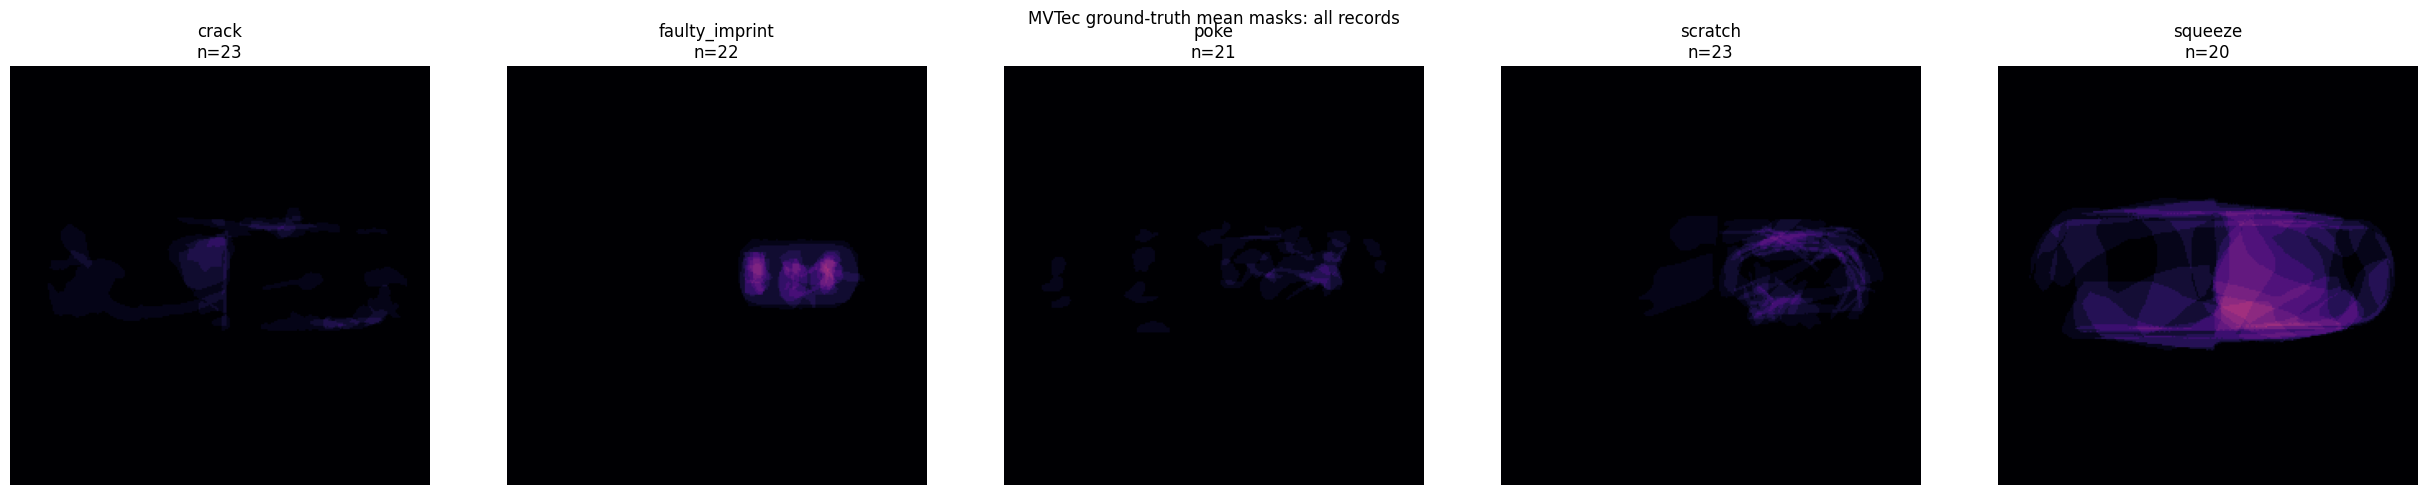

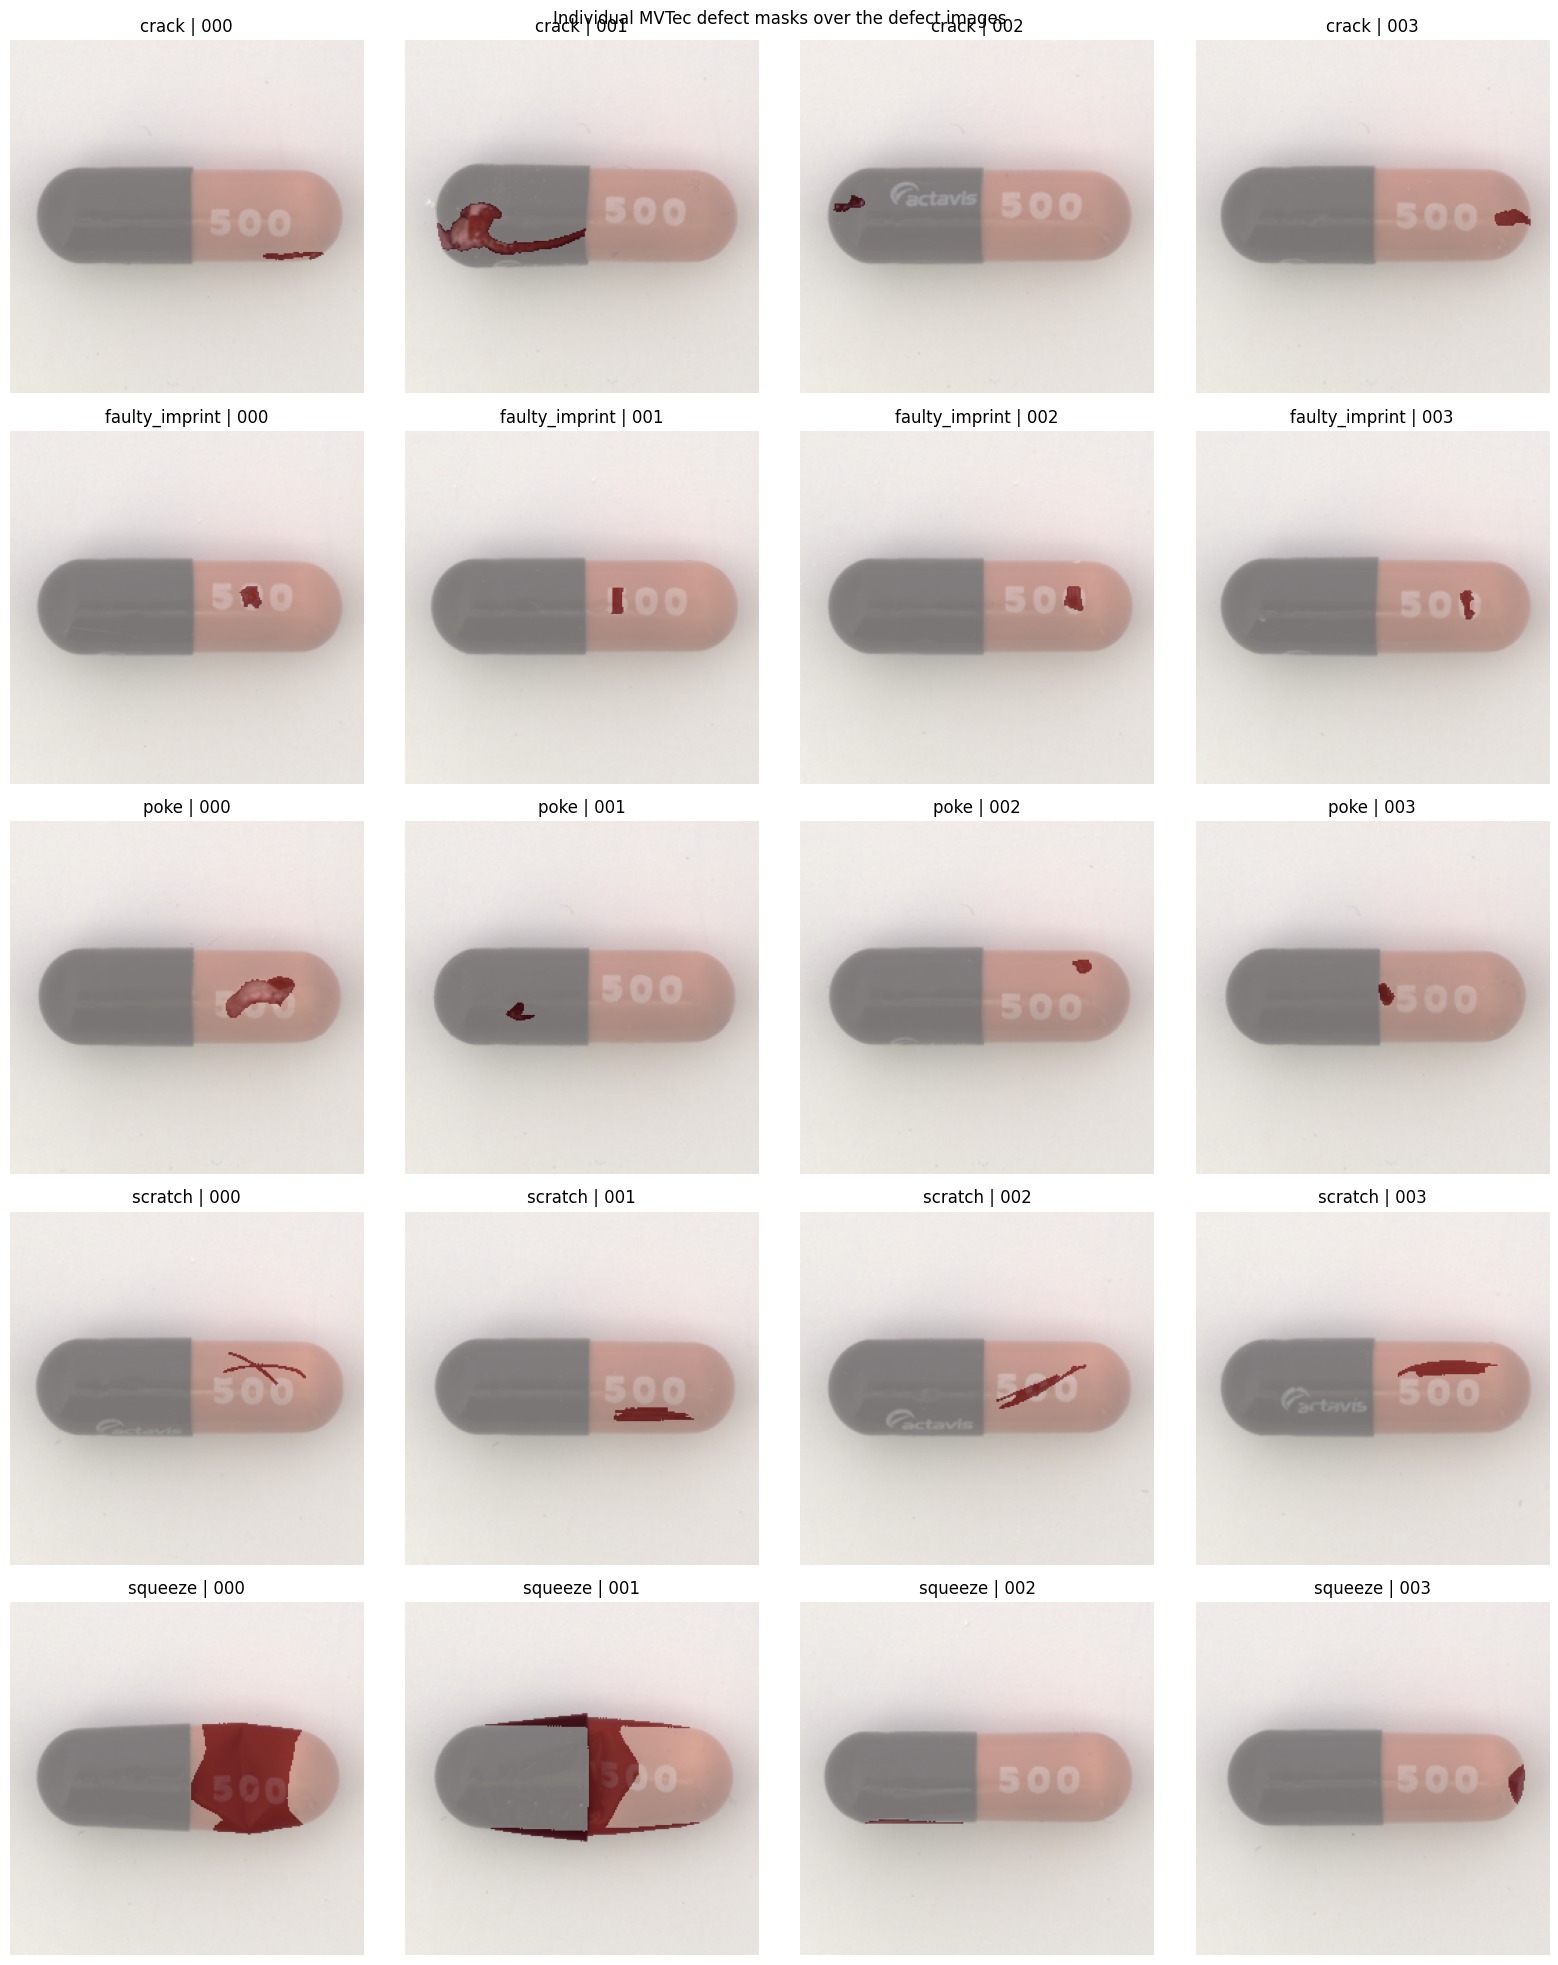

Saved diagnostics: /kaggle/working/type_conditioned_generalized_severity_v3_capsule/ground_truth_mean_masks_all.png /kaggle/working/type_conditioned_generalized_severity_v3_capsule/ground_truth_mask_examples.png


In [5]:
def prepare_records(records):
    prepared = []
    for record in records:
        defect_image = load_image_tensor(record["image_path"])
        full_mask = load_mask_tensor(record["mask_path"])
        if int(full_mask.sum().item()) < MIN_MASK_PIXELS:
            print("Skipping nearly empty mask:", record["mask_path"])
            continue
        prepared.append({
            **record,
            "defect_image": defect_image,
            "full_mask": full_mask,
            "type_id": type_to_id[record["defect_type"]],
        })
    return prepared


all_prepared_by_type = {
    name: prepare_records(all_records_by_type[name])
    for name in type_names
}
train_prepared_by_type = {
    name: prepare_records(train_records_by_type[name])
    for name in type_names
}
val_prepared_by_type = {
    name: prepare_records(val_records_by_type[name])
    for name in type_names
}


def mask_statistics(prepared_records):
    masks = torch.stack([record["full_mask"] for record in prepared_records])
    rows = []
    for index, record in enumerate(prepared_records):
        mask = masks[index, 0]
        coordinates = torch.nonzero(mask > 0.5, as_tuple=False)
        y0, x0 = coordinates.min(dim=0).values.tolist()
        y1, x1 = coordinates.max(dim=0).values.tolist()
        foreground = estimate_foreground(
            record["defect_image"].unsqueeze(0)
        )[0, 0]
        overlap = ((mask > 0.5) & (foreground > 0.5)).float().sum()
        rows.append({
            "defect_type": record["defect_type"],
            "image_path": record["image_path"],
            "area_fraction": float(mask.mean().item()),
            "centroid_y": float(coordinates[:, 0].float().mean().item() / IMAGE_SIZE),
            "centroid_x": float(coordinates[:, 1].float().mean().item() / IMAGE_SIZE),
            "bbox_height": float((y1 - y0 + 1) / IMAGE_SIZE),
            "bbox_width": float((x1 - x0 + 1) / IMAGE_SIZE),
            "foreground_overlap": float((overlap / (mask.sum() + 1e-6)).item()),
        })
    return rows


all_stats = []
for name in type_names:
    rows = mask_statistics(all_prepared_by_type[name])
    all_stats.extend(rows)
    area = np.array([row["area_fraction"] for row in rows])
    cy = np.array([row["centroid_y"] for row in rows])
    cx = np.array([row["centroid_x"] for row in rows])
    overlap = np.array([row["foreground_overlap"] for row in rows])
    print(
        f"{name:18s} n={len(rows):2d} | "
        f"area={area.mean():.4f} +/- {area.std():.4f} | "
        f"centroid=(y={cy.mean():.3f}, x={cx.mean():.3f}) | "
        f"foreground overlap={overlap.mean():.3f}"
    )

(OUTPUT_DIR / "all_mask_statistics.json").write_text(
    json.dumps(all_stats, indent=2)
)

figure, axes = plt.subplots(1, len(type_names), figsize=(5 * len(type_names), 5))
axes = np.atleast_1d(axes)
for axis, name in zip(axes, type_names):
    masks = torch.stack([row["full_mask"] for row in all_prepared_by_type[name]])
    mean_mask = masks.float().mean(dim=0)[0]
    axis.imshow(mean_mask, cmap="magma", vmin=0, vmax=1)
    axis.set_title(f"{name}\nn={len(masks)}")
    axis.axis("off")
figure.suptitle("MVTec ground-truth mean masks: all records")
figure.tight_layout()
all_mean_path = OUTPUT_DIR / "ground_truth_mean_masks_all.png"
figure.savefig(all_mean_path, dpi=160)
plt.show()
plt.close(figure)

columns = 4
figure, axes = plt.subplots(
    len(type_names), columns,
    figsize=(4 * columns, 4 * len(type_names)),
    squeeze=False,
)
for row_index, name in enumerate(type_names):
    examples = all_prepared_by_type[name][:columns]
    for column in range(columns):
        axis = axes[row_index, column]
        axis.axis("off")
        if column >= len(examples):
            continue
        record = examples[column]
        display = tensor_to_display(record["defect_image"])
        axis.imshow(display)
        axis.imshow(record["full_mask"][0], cmap="Reds", alpha=0.45)
        axis.set_title(f"{name} | {Path(record['image_path']).stem}")
figure.suptitle("Individual MVTec defect masks over the defect images")
figure.tight_layout()
examples_path = OUTPUT_DIR / "ground_truth_mask_examples.png"
figure.savefig(examples_path, dpi=160)
plt.show()
plt.close(figure)
print("Saved diagnostics:", all_mean_path, examples_path)

Saved generalized mask bank: /kaggle/working/type_conditioned_generalized_severity_v3_capsule/generalized_empirical_mask_bank_v3.pt
generalized coverage crack             : raw=0.2235 | 64-candidate=0.1703 over n=5 held-out masks
generalized coverage faulty_imprint    : raw=0.4252 | 64-candidate=0.4015 over n=4 held-out masks
generalized coverage poke              : raw=0.2046 | 64-candidate=0.1894 over n=4 held-out masks
generalized coverage scratch           : raw=0.2138 | 64-candidate=0.2920 over n=5 held-out masks
generalized coverage squeeze           : raw=0.4308 | 64-candidate=0.3947 over n=4 held-out masks


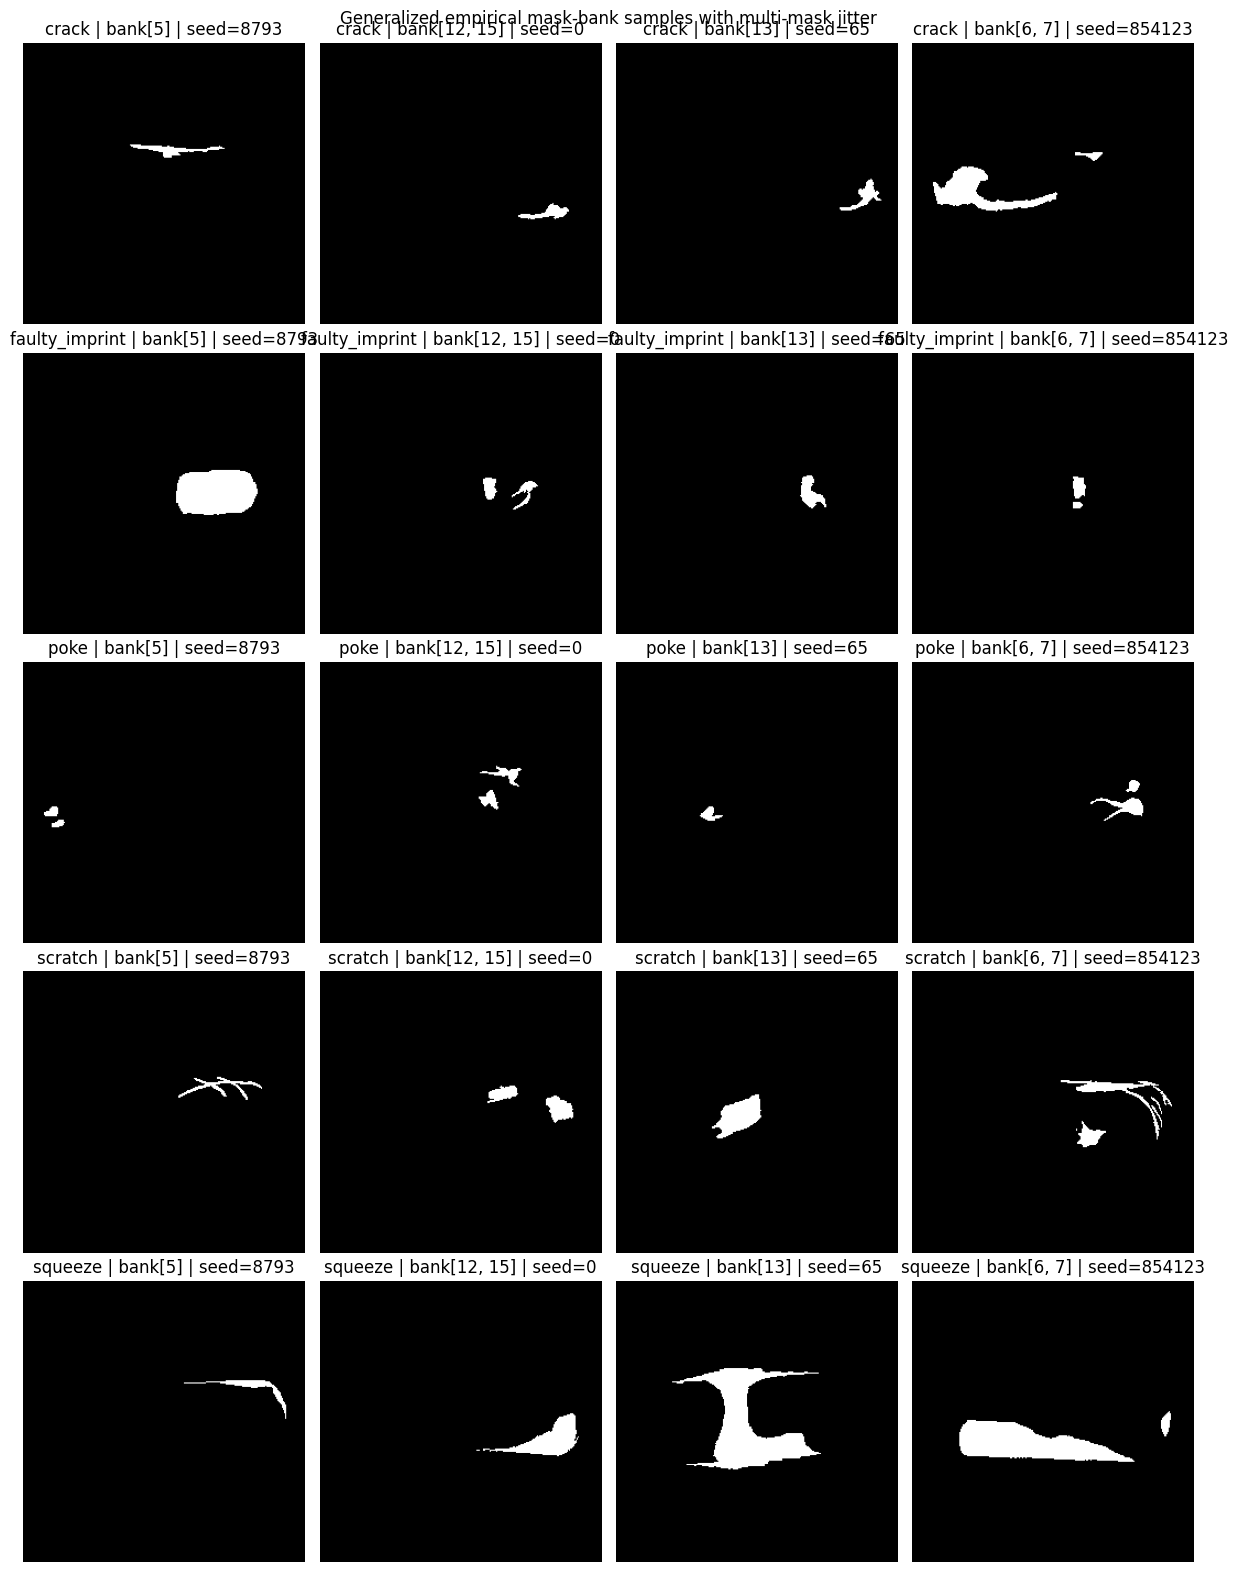

In [6]:
class GeneralizedEmpiricalMaskBank:
    """Training-mask bank with deterministic multi-mask and geometry sampling.

    It never reads an anomaly image at inference. A type-specific source mask
    is selected from training masks, optionally paired with a second source
    mask of the same type, then jittered. The returned mask is the exact mask
    used by the generator and is saved with its source indices.
    """
    def __init__(self, prepared_by_type):
        self.masks_by_type = {}
        self.source_paths_by_type = {}
        for name in type_names:
            records = prepared_by_type[name]
            if not records:
                raise RuntimeError(f"No usable training masks for {name}")
            self.masks_by_type[name] = torch.stack(
                [record["full_mask"].cpu() for record in records]
            ).float()
            self.source_paths_by_type[name] = [
                record["mask_path"] for record in records
            ]

    def _sample_one(self, name, rng, inference=True):
        masks = self.masks_by_type[name]
        index = rng.randrange(len(masks))
        mask = masks[index].clone()
        if inference:
            mask = apply_mask_jitter(
                mask,
                rng,
                max_translate=INFER_JITTER_TRANSLATE_PX,
                scale_low=INFER_JITTER_SCALE_LOW,
                scale_high=INFER_JITTER_SCALE_HIGH,
                max_degrees=INFER_JITTER_DEGREES,
                max_shear=INFER_JITTER_SHEAR,
                morph_probability=INFER_MORPH_JITTER_PROB,
                morph_radius=INFER_MORPH_RADIUS,
            )
        return mask, index

    def sample(self, name, seed, *, inference=True, device=None, context=None):
        if name not in self.masks_by_type:
            raise KeyError(f"Unknown type {name}; available={type_names}")
        rng = random.Random(int(seed))
        first_mask, first_index = self._sample_one(name, rng, inference)
        masks = [first_mask]
        source_indices = [first_index]
        if (
            MAX_MIX_COMPONENTS >= 2
            and len(self.masks_by_type[name]) > 1
            and rng.random() < MASK_MIX_PROB
        ):
            second_mask, second_index = self._sample_one(name, rng, inference)
            candidate = torch.maximum(first_mask, second_mask)
            if float(candidate.mean().item()) <= MAX_MASK_AREA_FRACTION:
                masks.append(second_mask)
                source_indices.append(second_index)
        mask = masks[0]
        for component in masks[1:]:
            mask = torch.maximum(mask, component)
        if int(mask.sum().item()) < MIN_MASK_PIXELS:
            mask = first_mask
            source_indices = [first_index]
        if CLIP_MASK_TO_CONTEXT_FOREGROUND and context is not None:
            foreground = estimate_foreground(context)
            clipped = mask.unsqueeze(0).to(foreground.device) * foreground
            if int(clipped.sum().item()) >= MIN_MASK_PIXELS:
                mask = clipped[0].cpu()
        if device is not None:
            mask = mask.to(device)
        return mask, source_indices

    def checkpoint(self):
        return {
            "version": "generalized_empirical_mask_bank_v3",
            "masks_by_type": self.masks_by_type,
            "source_paths_by_type": self.source_paths_by_type,
            "type_names": type_names,
            "type_to_id": type_to_id,
            "image_size": IMAGE_SIZE,
            "generalization": {
                "mask_mix_probability": MASK_MIX_PROB,
                "max_mix_components": MAX_MIX_COMPONENTS,
                "max_area_fraction": MAX_MASK_AREA_FRACTION,
                "train_appearance_augmentation_probability": TRAIN_APPEARANCE_AUG_PROB,
            },
            "jitter": {
                "translate_px": INFER_JITTER_TRANSLATE_PX,
                "scale_low": INFER_JITTER_SCALE_LOW,
                "scale_high": INFER_JITTER_SCALE_HIGH,
                "degrees": INFER_JITTER_DEGREES,
                "shear": INFER_JITTER_SHEAR,
                "morph_probability": INFER_MORPH_JITTER_PROB,
                "morph_radius": INFER_MORPH_RADIUS,
            },
        }


mask_bank = GeneralizedEmpiricalMaskBank(train_prepared_by_type)
torch.save(mask_bank.checkpoint(), MASK_BANK_PATH)
print("Saved generalized mask bank:", MASK_BANK_PATH)

# Compare raw bank coverage with coverage from 64 deterministic generalized
# candidates per type. Validation masks are never inserted into the bank.
coverage_rows = []
for name in type_names:
    train_masks = mask_bank.masks_by_type[name]
    for record in val_prepared_by_type[name]:
        target = record["full_mask"]
        raw_best = max(iou_score(candidate, target) for candidate in train_masks)
        generalized_best = 0.0
        best_seed = None
        for candidate_seed in range(1000, 1000 + GENERALIZATION_COVERAGE_SAMPLES):
            candidate, _ = mask_bank.sample(name, candidate_seed, inference=True)
            score = iou_score(candidate, target)
            if score > generalized_best:
                generalized_best = score
                best_seed = candidate_seed
        coverage_rows.append({
            "defect_type": name,
            "image_path": record["image_path"],
            "raw_bank_best_iou": raw_best,
            "generalized_bank_best_iou": generalized_best,
            "best_seed": best_seed,
        })
for name in type_names:
    rows = [row for row in coverage_rows if row["defect_type"] == name]
    if rows:
        raw = np.mean([row["raw_bank_best_iou"] for row in rows])
        generalized = np.mean([row["generalized_bank_best_iou"] for row in rows])
        print(
            f"generalized coverage {name:18s}: raw={raw:.4f} | "
            f"64-candidate={generalized:.4f} over n={len(rows)} held-out masks"
        )
(OUTPUT_DIR / "generalized_mask_bank_heldout_coverage.json").write_text(
    json.dumps(coverage_rows, indent=2)
)

figure, axes = plt.subplots(
    len(type_names), 4,
    figsize=(12, 3.2 * len(type_names)),
    squeeze=False,
)
for row_index, name in enumerate(type_names):
    for column, seed in enumerate([8793, 0, 65, 854123]):
        sampled, source_indices = mask_bank.sample(name, seed)
        axes[row_index, column].imshow(sampled[0], cmap="gray", vmin=0, vmax=1)
        axes[row_index, column].set_title(
            f"{name} | bank{source_indices} | seed={seed}"
        )
        axes[row_index, column].axis("off")
figure.suptitle("Generalized empirical mask-bank samples with multi-mask jitter")
figure.tight_layout()
bank_preview_path = OUTPUT_DIR / "generalized_empirical_mask_bank_preview.png"
figure.savefig(bank_preview_path, dpi=160)
plt.show()
plt.close(figure)


In [7]:
class NoisePredictionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.unet = UNet2DModel(
            sample_size=IMAGE_SIZE,
            in_channels=8,
            out_channels=3,
            layers_per_block=2,
            block_out_channels=(96, 192, 384, 768),
            down_block_types=(
                "DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D"
            ),
            up_block_types=(
                "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"
            ),
            norm_num_groups=32,
            act_fn="silu",
        )


    def forward(self, sample, timestep):
        return self.unet(sample, timestep).sample


if not NORMAL_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Frozen normal checkpoint not found: {NORMAL_CHECKPOINT}"
    )

base_model = NoisePredictionUNet()
normal_checkpoint = torch.load(NORMAL_CHECKPOINT, map_location="cpu")
base_state = normal_checkpoint.get("model", normal_checkpoint)
base_state = strip_module_prefix(base_state)
missing, unexpected = base_model.load_state_dict(base_state, strict=False)
if missing or unexpected:
    raise RuntimeError(
        f"Normal checkpoint mismatch. Missing={missing[:3]}, "
        f"unexpected={unexpected[:3]}"
    )
base_model = base_model.to(DEVICE).eval()
for parameter in base_model.parameters():
    parameter.requires_grad = False
if USE_MULTI_GPU:
    base_model = nn.DataParallel(base_model, device_ids=list(range(GPU_COUNT)))

train_scheduler = DDPMScheduler(
    num_train_timesteps=1000,
    beta_schedule="squaredcos_cap_v2",
    prediction_type="epsilon",
    clip_sample=False,
)
sample_scheduler = DDIMScheduler.from_config(train_scheduler.config)
ALPHAS_CUMPROD = train_scheduler.alphas_cumprod.to(DEVICE)
print("Frozen normal backbone loaded on", DEVICE)

Frozen normal backbone loaded on cuda


Generalized adapter samples per epoch: 1755
Per-type counts in one epoch: {'crack': 351, 'faulty_imprint': 351, 'poke': 351, 'scratch': 351, 'squeeze': 351}


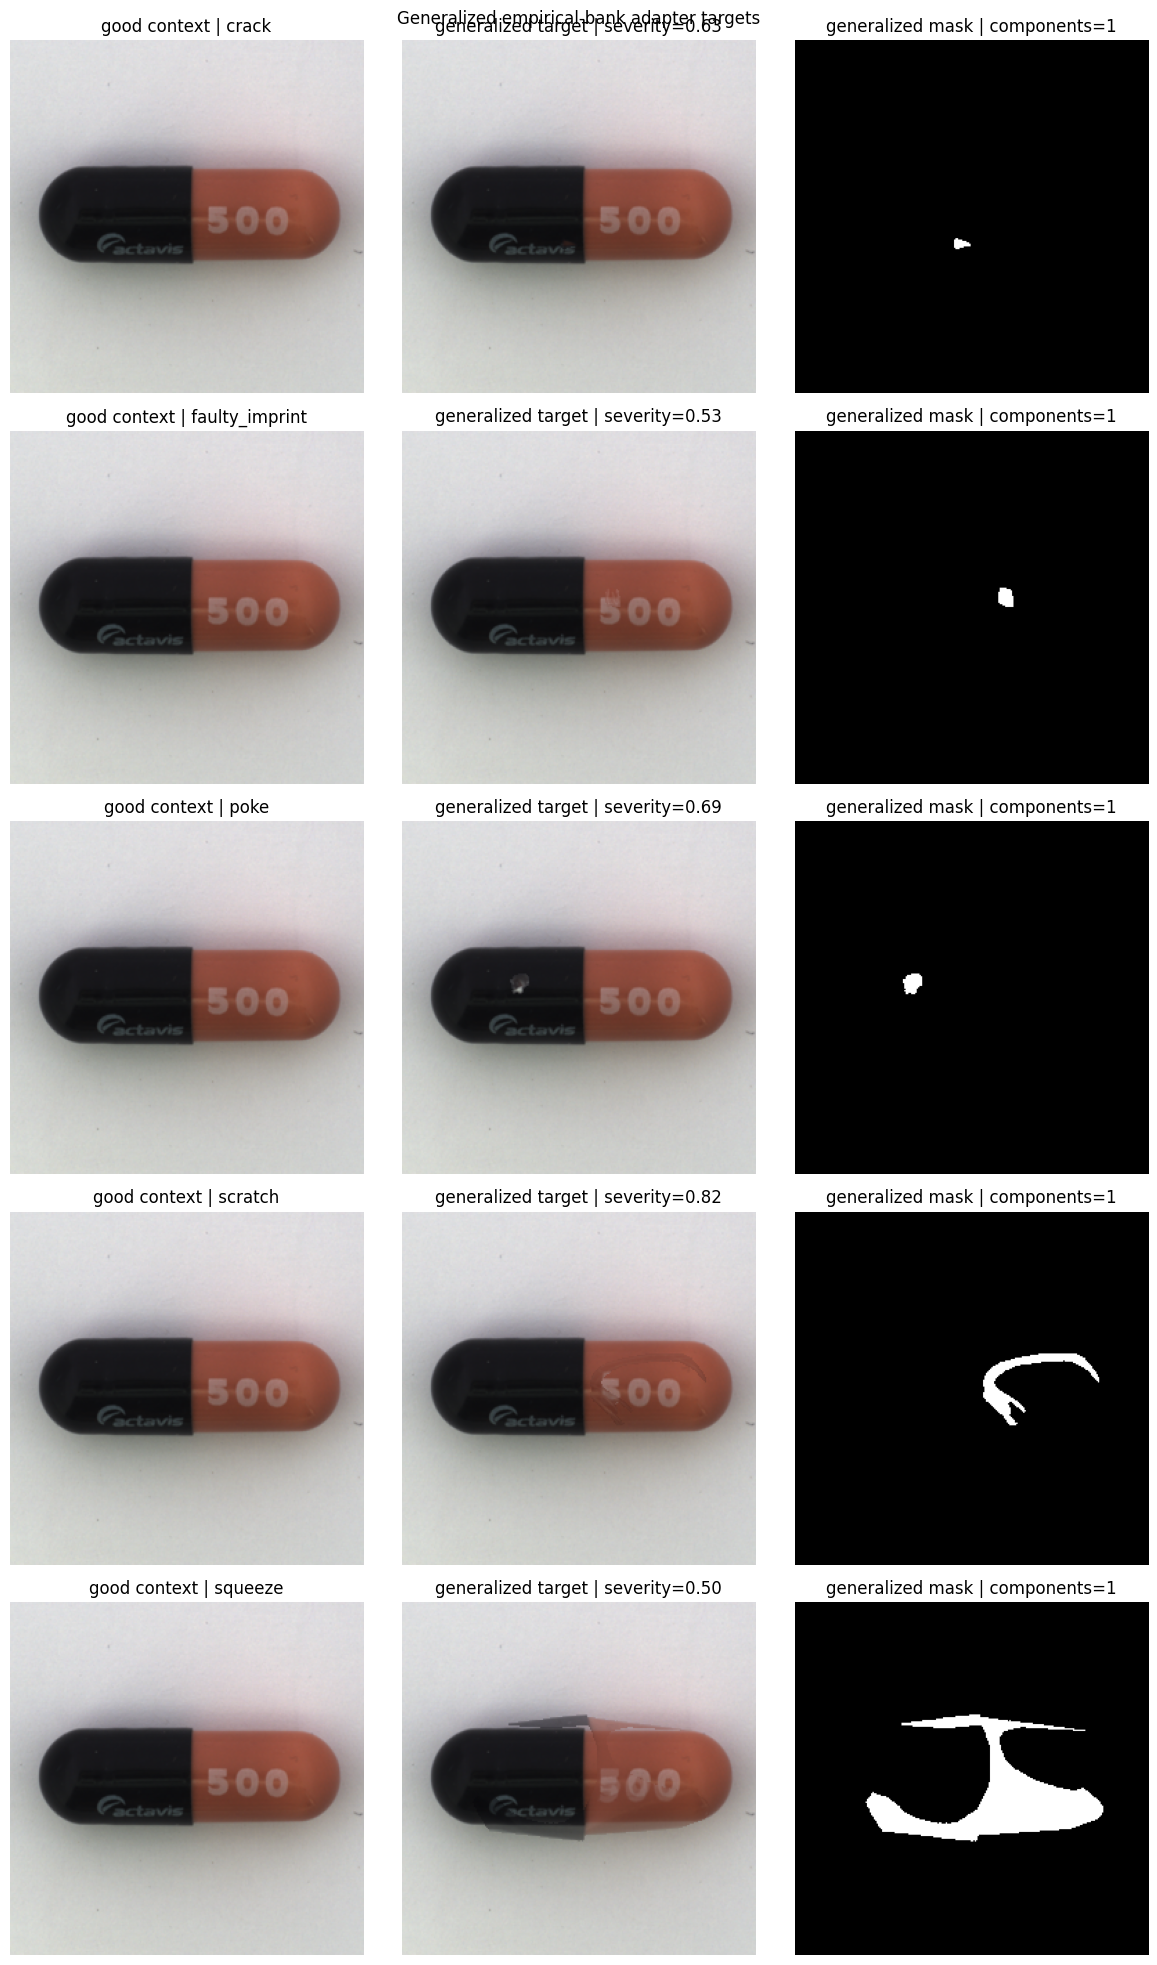

In [8]:
def augment_defect_appearance(image, rng):
    """Small appearance perturbation applied only to defect target components."""
    if rng.random() >= TRAIN_APPEARANCE_AUG_PROB:
        return image
    image01 = (image * 0.5 + 0.5).clamp(0, 1)
    image01 = TF.adjust_brightness(image01, rng.uniform(0.85, 1.15))
    image01 = TF.adjust_contrast(image01, rng.uniform(0.85, 1.20))
    image01 = TF.adjust_saturation(image01, rng.uniform(0.85, 1.15))
    return image01.clamp(0, 1) * 2.0 - 1.0


def prepare_target_component(record, rng, jitter=True):
    defect_image = record["defect_image"].clone()
    core_mask = record["full_mask"].clone()
    if jitter:
        defect_image, core_mask = apply_affine_pair(
            defect_image,
            core_mask,
            rng,
            max_translate=TRAIN_JITTER_TRANSLATE_PX,
            scale_low=TRAIN_JITTER_SCALE_LOW,
            scale_high=TRAIN_JITTER_SCALE_HIGH,
            max_degrees=TRAIN_JITTER_DEGREES,
            max_shear=TRAIN_JITTER_SHEAR,
        )
        if (
            TRAIN_MORPH_RADIUS > 0
            and rng.random() < TRAIN_MORPH_JITTER_PROB
        ):
            if rng.random() < 0.5:
                core_mask = dilate(core_mask.unsqueeze(0), TRAIN_MORPH_RADIUS)[0]
            else:
                core_mask = erode(core_mask.unsqueeze(0), TRAIN_MORPH_RADIUS)[0]
            core_mask = (core_mask > 0.5).float()
    defect_image = augment_defect_appearance(defect_image, rng)
    if int(core_mask.sum().item()) < MIN_MASK_PIXELS:
        defect_image = record["defect_image"].clone()
        core_mask = record["full_mask"].clone()
    return defect_image, core_mask


def make_training_example(context, record, rng, secondary_record=None, jitter=True):
    components = [record]
    if secondary_record is not None:
        components.append(secondary_record)
    defect_canvas = context.clone()
    combined_mask = torch.zeros_like(record["full_mask"])
    component_masks = []
    for component in components:
        defect_image, component_mask = prepare_target_component(
            component, rng, jitter=jitter
        )
        component_masks.append(component_mask)
        defect_canvas = torch.where(
            component_mask.expand_as(defect_canvas) > 0.5,
            defect_image,
            defect_canvas,
        )
        combined_mask = torch.maximum(combined_mask, component_mask)
    if float(combined_mask.mean().item()) > MAX_MASK_AREA_FRACTION:
        defect_image, combined_mask = prepare_target_component(record, rng, jitter=jitter)
        defect_canvas = torch.where(
            combined_mask.expand_as(defect_canvas) > 0.5,
            defect_image,
            context,
        )
    severity = rng.uniform(SEVERITY_LOW, SEVERITY_HIGH)
    gate = soft_generation_mask(combined_mask.unsqueeze(0), radius=3)[0]
    raw_target = context * (1 - combined_mask) + defect_canvas * combined_mask
    target = (
        context * (1 - severity * gate)
        + raw_target * (severity * gate)
    ).clamp(-1, 1)
    return {
        "context": context,
        "target": target,
        "mask": combined_mask,
        "type_id": torch.tensor(record["type_id"], dtype=torch.long),
        "severity": torch.tensor(severity, dtype=torch.float32),
        "defect_type": record["defect_type"],
        "num_components": torch.tensor(len(components), dtype=torch.long),
    }


class GeneralizedEmpiricalAnomalyDataset(Dataset):
    def __init__(self, normal_paths, records_by_type, length, seed=42, jitter=True):
        self.normal_paths = list(normal_paths)
        self.records_by_type = records_by_type
        self.type_names = [name for name in type_names if records_by_type[name]]
        self.length = int(length)
        self.seed = int(seed)
        self.epoch = 0
        self.jitter = jitter

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        name = self.type_names[index % len(self.type_names)]
        rng = random.Random(self.seed + 1000003 * self.epoch + index)
        records = self.records_by_type[name]
        record = records[rng.randrange(len(records))]
        secondary_record = None
        if len(records) > 1 and rng.random() < MASK_MIX_PROB:
            candidate = records[rng.randrange(len(records))]
            if candidate["image_path"] != record["image_path"]:
                secondary_record = candidate
        normal_path = self.normal_paths[(index + 17 * self.epoch) % len(self.normal_paths)]
        context = load_image_tensor(normal_path)
        return make_training_example(
            context,
            record,
            rng,
            secondary_record=secondary_record,
            jitter=self.jitter,
        )


samples_per_epoch = len(type_names) * max(
    4,
    math.ceil(len(normal_paths) * AUGMENT_FACTOR / len(type_names)),
)
train_dataset = GeneralizedEmpiricalAnomalyDataset(
    normal_paths,
    train_prepared_by_type,
    length=samples_per_epoch,
    seed=SEED,
    jitter=True,
)
train_loader = DataLoader(
    train_dataset,
    batch_size=ADAPTER_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
print("Generalized adapter samples per epoch:", len(train_dataset))
print("Per-type counts in one epoch:", {
    name: sum(
        1 for index in range(len(train_dataset))
        if train_dataset.type_names[index % len(train_dataset.type_names)] == name
    )
    for name in train_dataset.type_names
})

figure, axes = plt.subplots(
    len(type_names), 3,
    figsize=(12, 4 * len(type_names)),
    squeeze=False,
)
preview_rng = random.Random(SEED + 9000)
preview_context = load_image_tensor(normal_paths[0])
for row_index, name in enumerate(type_names):
    record = train_prepared_by_type[name][0]
    example = make_training_example(preview_context, record, preview_rng, jitter=False)
    axes[row_index, 0].imshow(tensor_to_display(example["context"]))
    axes[row_index, 0].set_title(f"good context | {name}")
    axes[row_index, 1].imshow(tensor_to_display(example["target"]))
    axes[row_index, 1].set_title(
        f"generalized target | severity={example['severity'].item():.2f}"
    )
    axes[row_index, 2].imshow(example["mask"][0], cmap="gray")
    axes[row_index, 2].set_title(
        f"generalized mask | components={example['num_components'].item()}"
    )
    for column in range(3):
        axes[row_index, column].axis("off")
figure.suptitle("Generalized empirical-bank adapter targets")
figure.tight_layout()
training_preview_path = OUTPUT_DIR / "generalized_training_target_preview.png"
figure.savefig(training_preview_path, dpi=160)
plt.show()
plt.close(figure)


In [9]:
def group_count(channels):
    for groups in (32, 16, 8, 4, 2, 1):
        if channels % groups == 0:
            return groups
    return 1


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dimension):
        super().__init__()
        self.dimension = dimension

    def forward(self, timesteps):
        half = self.dimension // 2
        scale = math.log(10000) / max(1, half - 1)
        frequencies = torch.exp(
            torch.arange(half, device=timesteps.device, dtype=torch.float32) * -scale
        )
        angles = timesteps.float().view(-1, 1) * frequencies.view(1, -1)
        embedding = torch.cat([angles.sin(), angles.cos()], dim=1)
        if self.dimension % 2:
            embedding = F.pad(embedding, (0, 1))
        return embedding


class FiLMResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, condition_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(group_count(in_channels), in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(group_count(out_channels), out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.condition = nn.Linear(condition_dim, 2 * out_channels)
        self.skip = (
            nn.Conv2d(in_channels, out_channels, 1)
            if in_channels != out_channels else nn.Identity()
        )

    def forward(self, x, condition):
        hidden = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.condition(condition).chunk(2, dim=1)
        hidden = self.norm2(hidden)
        hidden = hidden * (1 + scale[:, :, None, None]) + shift[:, :, None, None]
        hidden = self.conv2(F.silu(hidden))
        return hidden + self.skip(x)


class TypeConditionedResidualAdapterV2(nn.Module):
    def __init__(self, num_types, type_dim=16, appearance_z_dim=4,
                 base=48, time_dim=64, condition_dim=128):
        super().__init__()
        self.type_embedding = nn.Embedding(num_types, type_dim)
        self.appearance_z_dim = appearance_z_dim
        self.type_dim = type_dim
        self.time_embedding = SinusoidalTimeEmbedding(time_dim)
        self.condition_mlp = nn.Sequential(
            nn.Linear(time_dim + type_dim + 1, condition_dim),
            nn.SiLU(),
            nn.Linear(condition_dim, condition_dim),
        )
        # sample + core mask + soft gate + visible normal + foreground + z
        input_channels = 3 + 1 + 1 + 3 + 1 + appearance_z_dim
        self.input_projection = nn.Conv2d(input_channels, base, 3, padding=1)
        self.enc1 = FiLMResidualBlock(base, base, condition_dim)
        self.down1 = nn.Conv2d(base, base * 2, 4, stride=2, padding=1)
        self.enc2 = FiLMResidualBlock(base * 2, base * 2, condition_dim)
        self.down2 = nn.Conv2d(base * 2, base * 4, 4, stride=2, padding=1)
        self.enc3 = FiLMResidualBlock(base * 4, base * 4, condition_dim)
        self.bottleneck = FiLMResidualBlock(base * 4, base * 4, condition_dim)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 4, stride=2, padding=1)
        self.dec2 = FiLMResidualBlock(base * 4, base * 2, condition_dim)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 4, stride=2, padding=1)
        self.dec1 = FiLMResidualBlock(base * 2, base, condition_dim)
        self.output_norm = nn.GroupNorm(group_count(base), base)
        self.output = nn.Conv2d(base, 3, 3, padding=1)
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)

    def make_condition(self, timesteps, type_id, severity):
        type_vector = self.type_embedding(type_id)
        time_vector = self.time_embedding(timesteps)
        severity_vector = severity.view(-1, 1)
        return self.condition_mlp(
            torch.cat([time_vector, type_vector, severity_vector], dim=1)
        )

    def forward(self, sample, core_mask, gate, visible, foreground,
                appearance_z, timesteps, type_id, severity):
        condition = self.make_condition(timesteps, type_id, severity)
        x = torch.cat(
            [sample, core_mask, gate, visible, foreground, appearance_z], dim=1
        )
        e1 = self.enc1(self.input_projection(x), condition)
        e2 = self.enc2(self.down1(e1), condition)
        e3 = self.enc3(self.down2(e2), condition)
        hidden = self.bottleneck(e3, condition)
        hidden = self.up2(hidden)
        hidden = self.dec2(torch.cat([hidden, e2], dim=1), condition)
        hidden = self.up1(hidden)
        hidden = self.dec1(torch.cat([hidden, e1], dim=1), condition)
        return self.output(F.silu(self.output_norm(hidden)))


adapter = TypeConditionedResidualAdapterV2(
    num_types=len(type_names),
    type_dim=TYPE_DIM,
    appearance_z_dim=APPEARANCE_Z_DIM,
    base=ADAPTER_BASE_CHANNELS,
    time_dim=TIME_EMBED_DIM,
    condition_dim=CONDITION_DIM,
).to(DEVICE)
if USE_MULTI_GPU:
    adapter = nn.DataParallel(adapter, device_ids=list(range(GPU_COUNT)))

adapter_optimizer = torch.optim.AdamW(
    adapter.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.99),
    weight_decay=WEIGHT_DECAY,
)
adapter_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    adapter_optimizer,
    T_max=ADAPTER_EPOCHS,
    eta_min=LEARNING_RATE * 0.10,
)
adapter_scaler = make_grad_scaler()
adapter_history = []
print("Severity residual gain enabled:", SEVERITY_RESIDUAL_GAIN)
start_epoch = 1
latest_checkpoint_path = OUTPUT_DIR / "adapter_latest_v3.pt"
if RESUME_TRAINING and latest_checkpoint_path.exists():
    resume_checkpoint = torch.load(latest_checkpoint_path, map_location="cpu")
    resume_state = strip_module_prefix(resume_checkpoint["adapter"])
    missing, unexpected = unwrap_model(adapter).load_state_dict(resume_state, strict=False)
    if missing or unexpected:
        raise RuntimeError(
            f"Resume adapter checkpoint mismatch. Missing={missing[:3]}, "
            f"unexpected={unexpected[:3]}"
        )
    adapter_optimizer.load_state_dict(resume_checkpoint["optimizer"])
    adapter_scheduler.load_state_dict(resume_checkpoint["scheduler"])
    if resume_checkpoint.get("scaler"):
        adapter_scaler.load_state_dict(resume_checkpoint["scaler"])
    adapter_history = resume_checkpoint.get("history", [])
    start_epoch = int(resume_checkpoint["epoch"]) + 1
    print(f"Resuming adapter at epoch {start_epoch} from {latest_checkpoint_path}")


if RUN_TRAINING:
    base_model.eval()
    for epoch in range(start_epoch, ADAPTER_EPOCHS + 1):
        train_dataset.epoch = epoch + 1000
        adapter.train()
        running = {
            "total": 0.0,
            "noise": 0.0,
            "masked_x0": 0.0,
            "outside": 0.0,
            "ssim": 0.0,
            "edge": 0.0,
        }
        start = time.time()
        t=1
        for batch in train_loader:
            context = batch["context"].to(DEVICE, non_blocking=True)
            target = batch["target"].to(DEVICE, non_blocking=True)
            core_mask = batch["mask"].to(DEVICE, non_blocking=True)
            type_id = batch["type_id"].to(DEVICE, non_blocking=True)
            severity = batch["severity"].to(DEVICE, non_blocking=True)
            batch_size = target.shape[0]
            gate = soft_generation_mask(core_mask, radius=3)
            visible = context * (1 - core_mask)
            foreground = estimate_foreground(context)
            timesteps = torch.randint(
                0, 1000, (batch_size,), device=DEVICE, dtype=torch.long
            )
            noise = torch.randn_like(target)
            noisy = train_scheduler.add_noise(target, noise, timesteps)
            appearance_z = torch.randn(
                batch_size,
                APPEARANCE_Z_DIM,
                IMAGE_SIZE,
                IMAGE_SIZE,
                device=DEVICE,
            )
            base_input = torch.cat([noisy, core_mask, visible, foreground], dim=1)
            adapter_optimizer.zero_grad(set_to_none=True)
            with torch.inference_mode():
                with amp_context():
                    base_noise = base_model(base_input, timesteps)
            with amp_context():
                adapter_delta = adapter(
                    noisy,
                    core_mask,
                    gate,
                    visible,
                    foreground,
                    appearance_z,
                    timesteps,
                    type_id,
                    severity,
                )
                severity_gain = severity.view(-1, 1, 1, 1).clamp(0.0, 1.0) if SEVERITY_RESIDUAL_GAIN else 1.0
                predicted_noise = base_noise + ADAPTER_SCALE * severity_gain * adapter_delta * gate
                noise_weight = 0.20 + 0.80 * gate
                noise_loss = (
                    (predicted_noise - noise).pow(2) * noise_weight
                ).mean()
                alpha_bar = ALPHAS_CUMPROD[timesteps].view(-1, 1, 1, 1)
                predicted_x0 = (
                    noisy - torch.sqrt(1 - alpha_bar) * predicted_noise
                ) / torch.sqrt(alpha_bar)
                predicted_x0 = predicted_x0.clamp(-1, 1)
                masked_x0 = (
                    (predicted_x0 - target).abs() * core_mask
                ).sum() / (3 * core_mask.sum() + 1e-6)
                outside = (
                    (predicted_x0 - context).abs() * (1 - gate)
                ).sum() / (3 * (1 - gate).sum() + 1e-6)
                generated01 = predicted_x0 * 0.5 + 0.5
                target01 = target * 0.5 + 0.5
                region = dilate(core_mask, 3)
                band = boundary_band(core_mask, 3)
                time_weight = alpha_bar.sqrt()
                ssim_loss = masked_mean(
                    local_ssim_loss_map(generated01, target01, window_size=7),
                    region,
                    time_weight,
                )
                edge_map = (
                    sobel_magnitude(generated01)
                    - sobel_magnitude(target01)
                ).abs()
                edge_loss = masked_mean(edge_map, band, time_weight)
                loss = (
                    noise_loss
                    + 0.30 * masked_x0
                    + 0.06 * outside
                    + 0.10 * ssim_loss
                    + 0.05 * edge_loss
                )
            if USE_AMP:
                adapter_scaler.scale(loss).backward()
                adapter_scaler.unscale_(adapter_optimizer)
                torch.nn.utils.clip_grad_norm_(adapter.parameters(), 1.0)
                adapter_scaler.step(adapter_optimizer)
                adapter_scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(adapter.parameters(), 1.0)
                adapter_optimizer.step()
            running["total"] += float(loss.item())
            running["noise"] += float(noise_loss.item())
            running["masked_x0"] += float(masked_x0.item())
            running["outside"] += float(outside.item())
            running["ssim"] += float(ssim_loss.item())
            running["edge"] += float(edge_loss.item())
            #print(f"Epoch [{epoch}] | Batch [{t}] | Loss: {loss:.4f}")
            t+= 1
        adapter_scheduler.step()
        count = max(1, len(train_loader))
        summary = {key: value / count for key, value in running.items()}
        summary["epoch"] = epoch
        summary["learning_rate"] = adapter_optimizer.param_groups[0]["lr"]
        summary["seconds"] = time.time() - start
        adapter_history.append(summary)
        if SAVE_EVERY_EPOCH:
            torch.save(
                {
                    "version": "type_conditioned_generalized_severity_v3_training_state",
                    "epoch": epoch,
                    "adapter": unwrap_model(adapter).state_dict(),
                    "optimizer": adapter_optimizer.state_dict(),
                    "scheduler": adapter_scheduler.state_dict(),
                    "scaler": adapter_scaler.state_dict() if USE_AMP else {},
                    "history": adapter_history,
                    "type_names": type_names,
                    "type_to_id": type_to_id,
                    "severity_range": [SEVERITY_LOW, SEVERITY_HIGH],
                    "normal_checkpoint": str(NORMAL_CHECKPOINT),
                },
                latest_checkpoint_path,
            )
        print(
                f"bank adapter | epoch {epoch:03d}/{ADAPTER_EPOCHS} | "
                f"total={summary['total']:.5f} | "
                f"noise={summary['noise']:.5f} | "
                f"masked_x0={summary['masked_x0']:.5f} | "
                f"outside={summary['outside']:.5f} | "
                f"ssim={summary['ssim']:.5f} | "
                f"edge={summary['edge']:.5f} | "
                f"lr={summary['learning_rate']:.2e} | "
                f"time={summary['seconds']:.1f}s"
                )
else:
    print("RUN_TRAINING=False: the adapter will be loaded in the next cell if available.")

Severity residual gain enabled: True
bank adapter | epoch 001/30 | total=0.06021 | noise=0.00243 | masked_x0=0.11397 | outside=0.06500 | ssim=0.16576 | edge=0.06221 | lr=7.98e-05 | time=994.4s
bank adapter | epoch 002/30 | total=0.05688 | noise=0.00247 | masked_x0=0.10381 | outside=0.06284 | ssim=0.16379 | edge=0.06226 | lr=7.92e-05 | time=968.8s
bank adapter | epoch 003/30 | total=0.05751 | noise=0.00249 | masked_x0=0.10794 | outside=0.06375 | ssim=0.15760 | edge=0.06115 | lr=7.82e-05 | time=969.5s
bank adapter | epoch 004/30 | total=0.05395 | noise=0.00258 | masked_x0=0.09686 | outside=0.06013 | ssim=0.15712 | edge=0.05978 | lr=7.69e-05 | time=970.8s
bank adapter | epoch 005/30 | total=0.05521 | noise=0.00225 | masked_x0=0.10329 | outside=0.06679 | ssim=0.15064 | edge=0.05809 | lr=7.52e-05 | time=973.8s
bank adapter | epoch 006/30 | total=0.05439 | noise=0.00251 | masked_x0=0.10024 | outside=0.06280 | ssim=0.15073 | edge=0.05920 | lr=7.31e-05 | time=974.0s
bank adapter | epoch 007/30

In [10]:
if RUN_TRAINING:
    torch.save(
        {
            "version": "type_conditioned_generalized_severity_v3",
            "adapter": unwrap_model(adapter).state_dict(),
            "architecture": "TypeConditionedResidualAdapterV2",
            "type_to_id": type_to_id,
            "type_names": type_names,
            "image_size": IMAGE_SIZE,
            "type_dim": TYPE_DIM,
            "appearance_z_dim": APPEARANCE_Z_DIM,
            "base_channels": ADAPTER_BASE_CHANNELS,
            "time_embed_dim": TIME_EMBED_DIM,
            "condition_dim": CONDITION_DIM,
            "normal_checkpoint": str(NORMAL_CHECKPOINT),
            "adapter_scale": ADAPTER_SCALE,
            "severity_range": [SEVERITY_LOW, SEVERITY_HIGH],
            "severity_residual_gain": SEVERITY_RESIDUAL_GAIN,
            "generalization": {
                "mask_mix_probability": MASK_MIX_PROB,
                "max_mix_components": MAX_MIX_COMPONENTS,
                "max_mask_area_fraction": MAX_MASK_AREA_FRACTION,
                "appearance_augmentation_probability": TRAIN_APPEARANCE_AUG_PROB,
            },
            "history": adapter_history,
        },
        ADAPTER_PATH,
    )
    (OUTPUT_DIR / "adapter_v3_history.json").write_text(
        json.dumps(adapter_history, indent=2)
    )
    (OUTPUT_DIR / "training_config_v3.json").write_text(json.dumps({
        "category": CATEGORY,
        "seed": SEED,
        "severity_low": SEVERITY_LOW,
        "severity_high": SEVERITY_HIGH,
        "severity_residual_gain": SEVERITY_RESIDUAL_GAIN,
        "mask_mix_probability": MASK_MIX_PROB,
        "max_mix_components": MAX_MIX_COMPONENTS,
        "max_mask_area_fraction": MAX_MASK_AREA_FRACTION,
        "train_appearance_augmentation_probability": TRAIN_APPEARANCE_AUG_PROB,
        "adapter_epochs": ADAPTER_EPOCHS,
        "resume_training": RESUME_TRAINING,
        "save_every_epoch": SAVE_EVERY_EPOCH,
        "samples_per_epoch": len(train_dataset),
        "type_names": type_names,
    }, indent=2))
    print("Saved V3 generalized adapter:", ADAPTER_PATH)
elif ADAPTER_PATH.exists():
    checkpoint = torch.load(ADAPTER_PATH, map_location="cpu")
    state = strip_module_prefix(checkpoint["adapter"])
    missing, unexpected = unwrap_model(adapter).load_state_dict(state, strict=False)
    if missing or unexpected:
        raise RuntimeError(
            f"V3 adapter checkpoint mismatch. Missing={missing[:3]}, "
            f"unexpected={unexpected[:3]}"
        )
    print("Loaded V3 generalized adapter:", ADAPTER_PATH)
elif latest_checkpoint_path.exists():
    checkpoint = torch.load(latest_checkpoint_path, map_location="cpu")
    state = strip_module_prefix(checkpoint["adapter"])
    missing, unexpected = unwrap_model(adapter).load_state_dict(state, strict=False)
    if missing or unexpected:
        raise RuntimeError(
            f"Latest V3 adapter checkpoint mismatch. Missing={missing[:3]}, "
            f"unexpected={unexpected[:3]}"
        )
    print("Loaded latest V3 training-state adapter:", latest_checkpoint_path)
else:
    raise FileNotFoundError(
        f"Neither {ADAPTER_PATH} nor {latest_checkpoint_path} exists. "
        "Set RUN_TRAINING=True first."
    )


Saved V3 generalized adapter: /kaggle/working/type_conditioned_generalized_severity_v3_capsule/type_conditioned_adapter_v3.pt


In [12]:
!zip -r stage3_capsule.zip /kaggle/working/type_conditioned_generalized_severity_v3_capsule 

  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/ (stored 0%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/training_config_v3.json (deflated 46%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/all_mask_statistics.json (deflated 88%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/generalized_empirical_mask_bank_v3.pt (deflated 100%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/ground_truth_mask_examples.png (deflated 0%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/adapter_latest_v3.pt (deflated 8%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/ground_truth_mean_masks_all.png (deflated 10%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/adapter_v3_history.json (deflated 71%)
  adding: kaggle/working/type_conditioned_generalized_severity_v3_capsule/generalized_empirical_

demo crack: source_indices=[0], seed=98745632, severity=0.85, mask_sha256=014f037a682824f47ef936b9bf8211608b8ac7fe599c4c09f8fb06322324bb64
demo faulty_imprint: source_indices=[10], seed=98753551, severity=0.85, mask_sha256=80d22e65b457cfd1583ec2fb08b25978f82f7929b28783484aaab961fbd8d653
demo poke: source_indices=[5], seed=98761470, severity=0.85, mask_sha256=444132d6c36cc1a5346b2f63ad8a4ea4144929146a9a341a93d1f93974284053
demo scratch: source_indices=[16, 13], seed=98769389, severity=0.85, mask_sha256=fb2faac0633ac57083d2c4955b25bc4d8a56bf6e1b99d4c6e498f93ab71e76d9
demo squeeze: source_indices=[3], seed=98777308, severity=0.85, mask_sha256=da5bc97ee25daa57f84336379ececb98525c07c53ad13f23976a1484257a2839


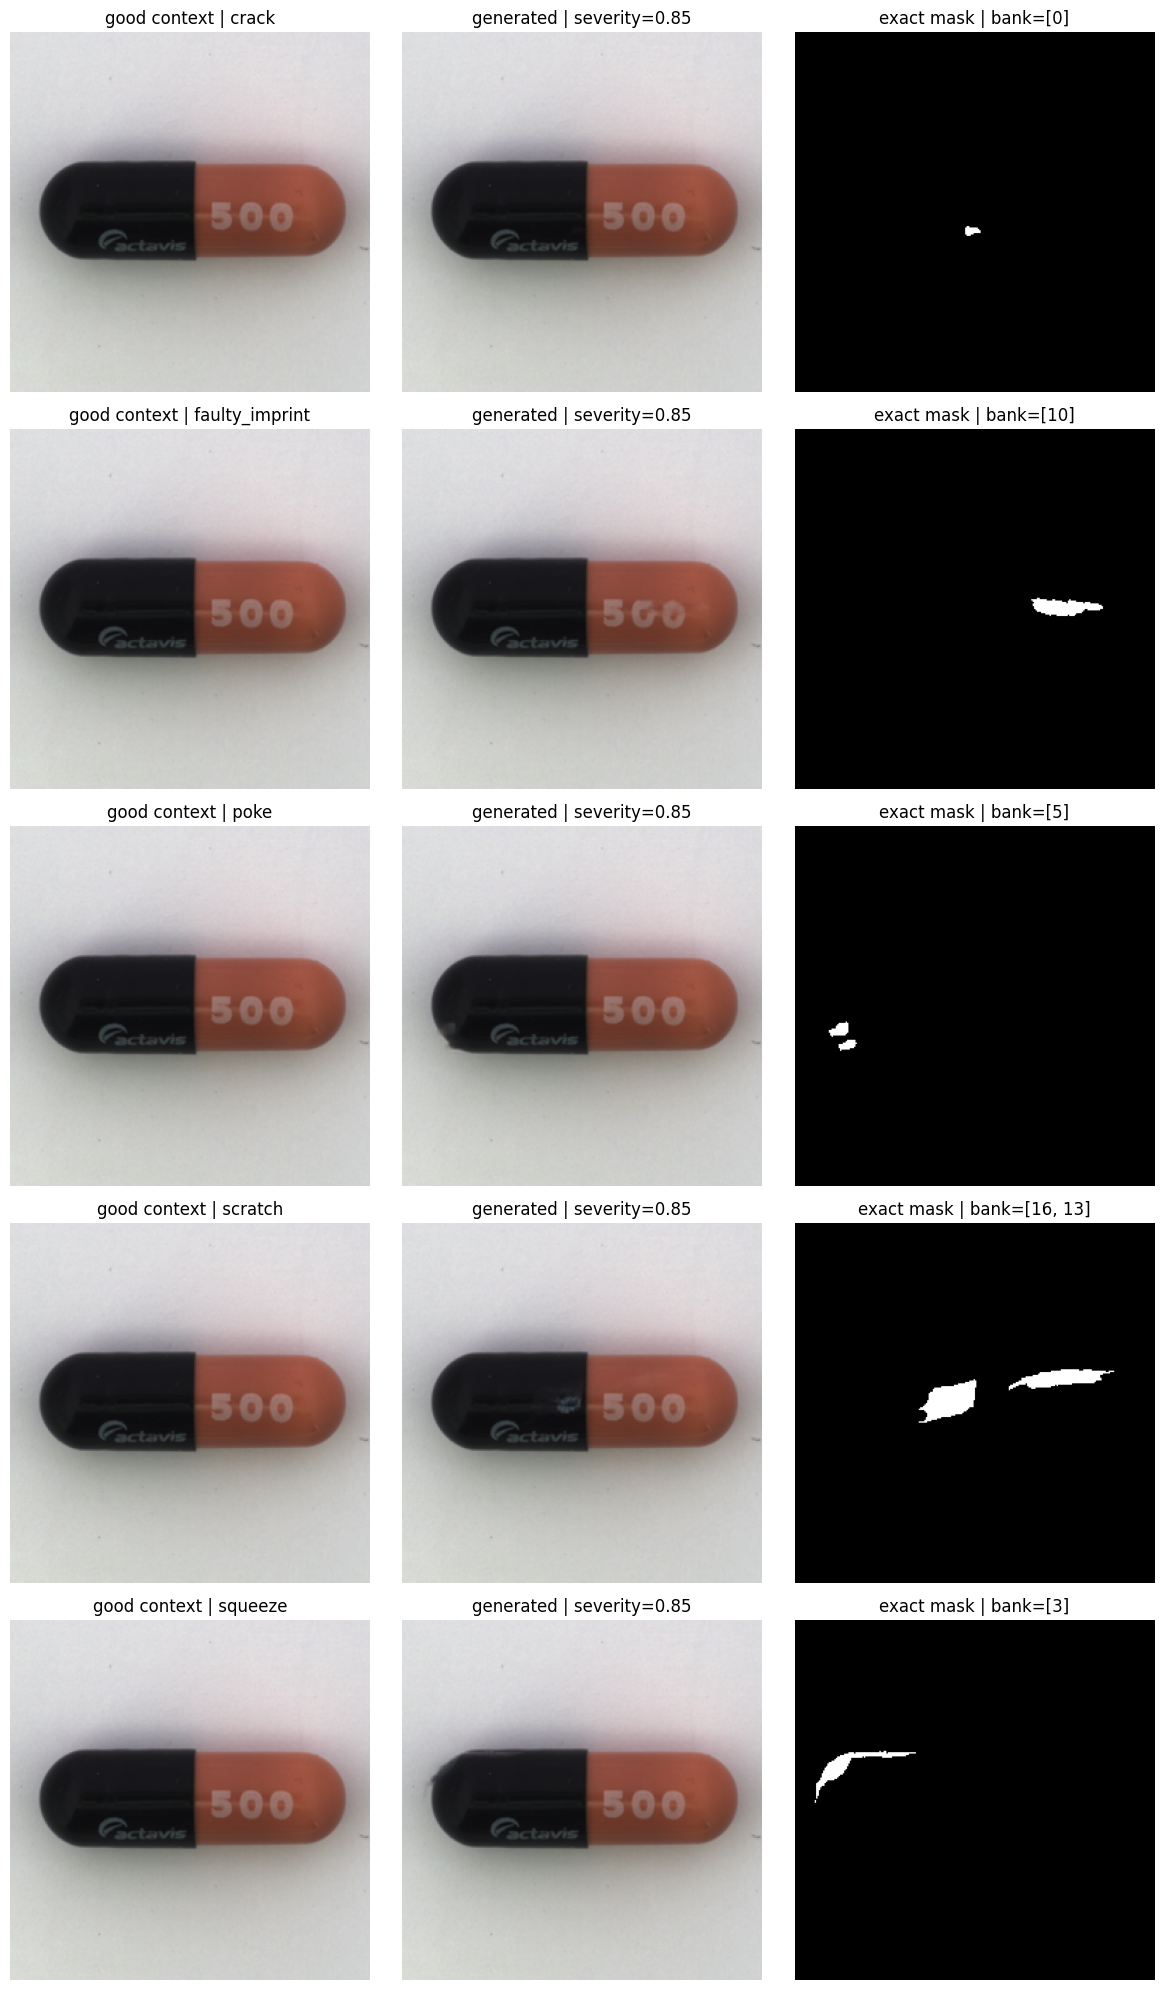

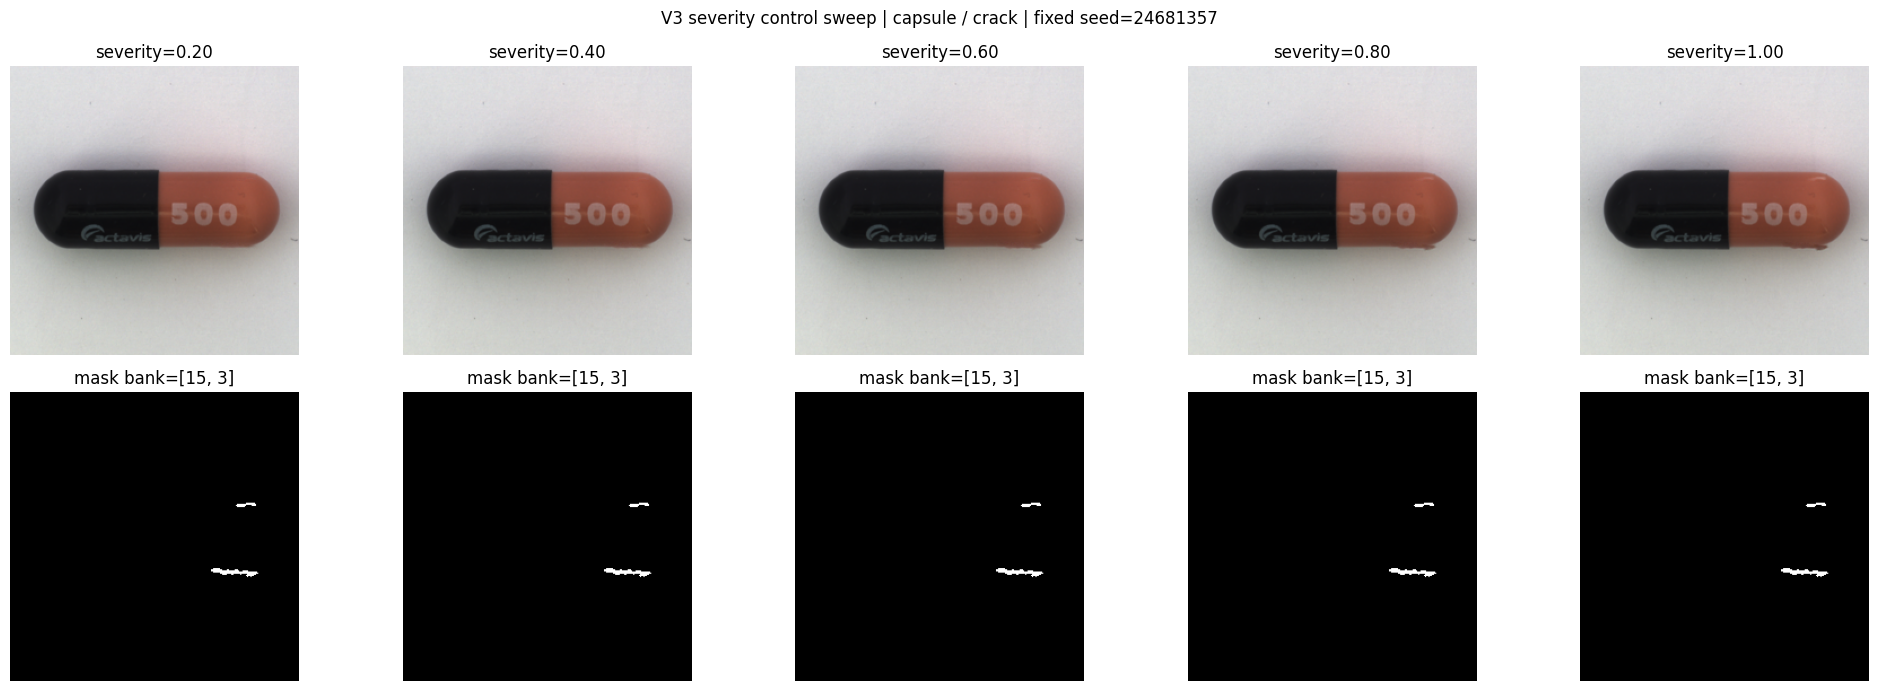

Severity sweep diagnostics:
{'severity': 0.2, 'seed': 24681357, 'defect_type': 'crack', 'source_indices': [15, 3], 'mean_masked_change': 0.058037733066708765, 'mean_outside_change': 2.1809113723646237e-05}
{'severity': 0.4, 'seed': 24681357, 'defect_type': 'crack', 'source_indices': [15, 3], 'mean_masked_change': 0.08248272817330136, 'mean_outside_change': 2.2658828881610764e-05}
{'severity': 0.6, 'seed': 24681357, 'defect_type': 'crack', 'source_indices': [15, 3], 'mean_masked_change': 0.12013282821014813, 'mean_outside_change': 2.4179476228259047e-05}
{'severity': 0.8, 'seed': 24681357, 'defect_type': 'crack', 'source_indices': [15, 3], 'mean_masked_change': 0.1694672207713757, 'mean_outside_change': 2.63371107168123e-05}
{'severity': 1.0, 'seed': 24681357, 'defect_type': 'crack', 'source_indices': [15, 3], 'mean_masked_change': 0.22772799174190167, 'mean_outside_change': 2.9550159007708425e-05}


In [13]:
@torch.no_grad()
def generate_from_generalized_bank(adapter, mask_bank, context, defect_type,
                                   severity=0.85, steps=30, seed=123,
                                   scale=1.5):
    """No-reference inference with explicit severity control.

    The same seed fixes the selected generalized mask and appearance noise;
    changing only severity therefore gives a controlled severity sweep.
    """
    adapter.eval()
    base_model.eval()
    severity = float(np.clip(severity, 0.0, 1.0))
    if defect_type not in type_to_id:
        raise KeyError(f"Unknown type {defect_type}; choose from {type_names}")
    batch = context.shape[0]
    if batch != 1:
        raise ValueError("Use one context image per generated sample for deterministic bank seeds.")
    core_mask, source_indices = mask_bank.sample(
        defect_type,
        seed,
        inference=True,
        device=context.device,
        context=context,
    )
    core_mask = core_mask.unsqueeze(0).float()
    if int(core_mask.sum().item()) < MIN_MASK_PIXELS:
        raise RuntimeError("Generalized empirical mask bank produced an empty mask.")
    gate = soft_generation_mask(core_mask, radius=3)
    visible = context * (1 - core_mask)
    foreground = estimate_foreground(context)
    type_id = torch.tensor([type_to_id[defect_type]], device=context.device)
    severity_tensor = torch.tensor(
        [severity], device=context.device, dtype=torch.float32
    )
    severity_gain = severity_tensor.view(-1, 1, 1, 1) if SEVERITY_RESIDUAL_GAIN else 1.0
    generator = torch.Generator(device=context.device)
    generator.manual_seed(int(seed))
    known_noise = torch.randn(
        context.shape, device=context.device, dtype=context.dtype, generator=generator
    )
    sample = torch.randn(
        context.shape, device=context.device, dtype=context.dtype, generator=generator
    )
    appearance_z = torch.randn(
        batch, APPEARANCE_Z_DIM, IMAGE_SIZE, IMAGE_SIZE,
        device=context.device, dtype=context.dtype, generator=generator
    )
    sample_scheduler.set_timesteps(steps, device=context.device)
    first_t = sample_scheduler.timesteps[0]
    first_batch = torch.full(
        (batch,), int(first_t.item()), device=context.device, dtype=torch.long
    )
    known_at_first = sample_scheduler.add_noise(context, known_noise, first_batch)
    sample = sample * gate + known_at_first * (1 - gate)
    for step_index, timestep in enumerate(sample_scheduler.timesteps):
        timestep_batch = torch.full(
            (batch,), int(timestep.item()), device=context.device, dtype=torch.long
        )
        base_input = torch.cat([sample, core_mask, visible, foreground], dim=1)
        with amp_context():
            base_noise = base_model(base_input, timestep_batch)
            adapter_delta = adapter(
                sample, core_mask, gate, visible, foreground, appearance_z,
                timestep_batch, type_id, severity_tensor,
            )
            predicted_noise = base_noise + float(scale) * severity_gain * adapter_delta * gate
        previous = sample_scheduler.step(
            predicted_noise, timestep, sample, eta=0.0
        ).prev_sample
        if step_index + 1 < len(sample_scheduler.timesteps):
            next_t = sample_scheduler.timesteps[step_index + 1]
            next_batch = torch.full(
                (batch,), int(next_t.item()), device=context.device, dtype=torch.long
            )
            known_next = sample_scheduler.add_noise(context, known_noise, next_batch)
        else:
            known_next = context
        sample = previous * gate + known_next * (1 - gate)
    return sample.clamp(-1, 1), core_mask, source_indices


def mean_masked_change(generated, context, mask):
    region = mask.expand_as(generated)
    return float(((generated - context).abs() * region).sum().item() / (region.sum().item() + 1e-6))


def mean_outside_change(generated, context, gate):
    region = (1 - gate).expand_as(generated)
    return float(((generated - context).abs() * region).sum().item() / (region.sum().item() + 1e-6))

def save_generation_artifacts(generated, mask, *, defect_type, severity,
                              seed, source_indices, prefix):
    """Persist an image, the exact binary mask, and auditable metadata."""
    image_path = OUTPUT_DIR / f"{prefix}.png"
    mask_path = OUTPUT_DIR / f"{prefix}_mask.png"
    metadata_path = OUTPUT_DIR / f"{prefix}.json"
    save_tensor_image(generated[0], image_path)
    save_tensor_mask(mask[0], mask_path)
    metadata = {
        "category": CATEGORY,
        "defect_type": defect_type,
        "severity": float(severity),
        "seed": int(seed),
        "source_indices": [int(index) for index in source_indices],
        "source_mask_paths": [
            mask_bank.source_paths_by_type[defect_type][int(index)]
            for index in source_indices
        ],
        "image_path": str(image_path),
        "exact_mask_path": str(mask_path),
        "mask_sha256": __import__("hashlib").sha256(mask_path.read_bytes()).hexdigest(),
        "normal_checkpoint": str(NORMAL_CHECKPOINT),
        "mask_bank": str(MASK_BANK_PATH),
        "inference_steps": int(INFER_STEPS),
        "adapter_scale": float(ADAPTER_SCALE),
        "severity_residual_gain": bool(SEVERITY_RESIDUAL_GAIN),
        "no_anomaly_reference_at_inference": True,
    }
    metadata_path.write_text(json.dumps(metadata, indent=2))
    return metadata


# One deterministic smoke test per type using the generalized bank. Each
# sample gets an exact mask file plus a JSON record of seed/source/severity.
if RUN_DEMOS:
    good_image = load_image_tensor(normal_paths[0]).unsqueeze(0).to(DEVICE)
    demo_rows = []
    for type_index, smoke_type in enumerate(type_names):
        seed = 98745632 + type_index * 7919
        smoke_image, smoke_mask, smoke_sources = generate_from_generalized_bank(
            adapter, mask_bank, good_image, smoke_type,
            severity=0.35, steps=INFER_STEPS, seed=seed, scale=ADAPTER_SCALE,
        )
        metadata = save_generation_artifacts(
            smoke_image,
            smoke_mask,
            defect_type=smoke_type,
            severity=0.35,
            seed=seed,
            source_indices=smoke_sources,
            prefix=f"v3_smoke_{smoke_type}",
        )
        demo_rows.append((smoke_type, smoke_image[0].detach().cpu(), smoke_mask[0, 0].detach().cpu(), smoke_sources))
        print(
            f"demo {smoke_type}: source_indices={smoke_sources}, seed={seed}, "
            f"severity=0.85, mask_sha256={metadata['mask_sha256']}"
        )
    figure, axes = plt.subplots(len(demo_rows), 3, figsize=(12, 4 * len(demo_rows)), squeeze=False)
    for row, (name, image, mask, sources) in enumerate(demo_rows):
        axes[row, 0].imshow(tensor_to_display(good_image[0])); axes[row, 0].set_title(f"good context | {name}")
        axes[row, 1].imshow(tensor_to_display(image)); axes[row, 1].set_title(f"generated | severity=0.85")
        axes[row, 2].imshow(mask, cmap="gray"); axes[row, 2].set_title(f"exact mask | bank={sources}")
        for column in range(3): axes[row, column].axis("off")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / "v3_no_reference_generation_demos.png", dpi=160)
    plt.show(); plt.close(figure)

# Fixed-seed severity sweep: only severity changes, while bank source and z
# stay deterministic. The saved JSON records masked/outside changes and the
# exact shared mask. By default one type is swept for a practical run; set
# SEVERITY_SWEEP_ALL_TYPES=True for a per-type controlled diagnostic.
if RUN_SEVERITY_SWEEP:
    good_image = load_image_tensor(normal_paths[0]).unsqueeze(0).to(DEVICE)
    sweep_types = type_names if SEVERITY_SWEEP_ALL_TYPES else [type_names[0]]
    sweep_seed = 24681357
    severity_values = np.linspace(
        SEVERITY_LOW, SEVERITY_HIGH, 5
    ).round(3).tolist()
    all_sweep_rows = []
    for sweep_type in sweep_types:
        sweep_rows = []
        figure, axes = plt.subplots(2, len(severity_values), figsize=(20, 7))
        for column, severity in enumerate(severity_values):
            generated, mask, sources = generate_from_generalized_bank(
                adapter, mask_bank, good_image, sweep_type,
                severity=severity, steps=INFER_STEPS,
                seed=sweep_seed, scale=ADAPTER_SCALE,
            )
            axes[0, column].imshow(tensor_to_display(generated[0]))
            axes[0, column].set_title(f"severity={severity:.2f}")
            axes[1, column].imshow(mask[0, 0].cpu(), cmap="gray")
            axes[1, column].set_title(f"mask bank={sources}")
            for row in range(2): axes[row, column].axis("off")
            row = {
                "severity": severity,
                "seed": sweep_seed,
                "defect_type": sweep_type,
                "source_indices": sources,
                "mean_masked_change": mean_masked_change(generated, good_image, mask),
                "mean_outside_change": mean_outside_change(generated, good_image, soft_generation_mask(mask, radius=3)),
            }
            all_sweep_rows.append(row)
            sweep_rows.append(row)
            # Every severity receives an image artifact and JSON metadata; the
            # exact mask is repeated intentionally because the seed is fixed.
            save_generation_artifacts(
                generated,
                mask,
                defect_type=sweep_type,
                severity=severity,
                seed=sweep_seed,
                source_indices=sources,
                prefix=f"v3_sweep_{sweep_type}_severity_{severity:.2f}",
            )
        figure.suptitle(f"V3 severity control sweep | {CATEGORY} / {sweep_type} | fixed seed={sweep_seed}")
        figure.tight_layout()
        figure.savefig(OUTPUT_DIR / f"v3_severity_sweep_{sweep_type}.png", dpi=160)
        plt.show(); plt.close(figure)
        (OUTPUT_DIR / f"v3_severity_sweep_{sweep_type}.json").write_text(
            json.dumps(sweep_rows, indent=2)
        )
    (OUTPUT_DIR / "v3_severity_sweep_all.json").write_text(
        json.dumps(all_sweep_rows, indent=2)
    )
    print("Severity sweep diagnostics:")
    for row in all_sweep_rows:
        print(row)


demo crack: source_indices=[0], seed=98745632, severity=0.85, mask_sha256=014f037a682824f47ef936b9bf8211608b8ac7fe599c4c09f8fb06322324bb64
demo faulty_imprint: source_indices=[10], seed=98753551, severity=0.85, mask_sha256=80d22e65b457cfd1583ec2fb08b25978f82f7929b28783484aaab961fbd8d653
demo poke: source_indices=[5], seed=98761470, severity=0.85, mask_sha256=444132d6c36cc1a5346b2f63ad8a4ea4144929146a9a341a93d1f93974284053
demo scratch: source_indices=[16, 13], seed=98769389, severity=0.85, mask_sha256=fb2faac0633ac57083d2c4955b25bc4d8a56bf6e1b99d4c6e498f93ab71e76d9
demo squeeze: source_indices=[3], seed=98777308, severity=0.85, mask_sha256=da5bc97ee25daa57f84336379ececb98525c07c53ad13f23976a1484257a2839


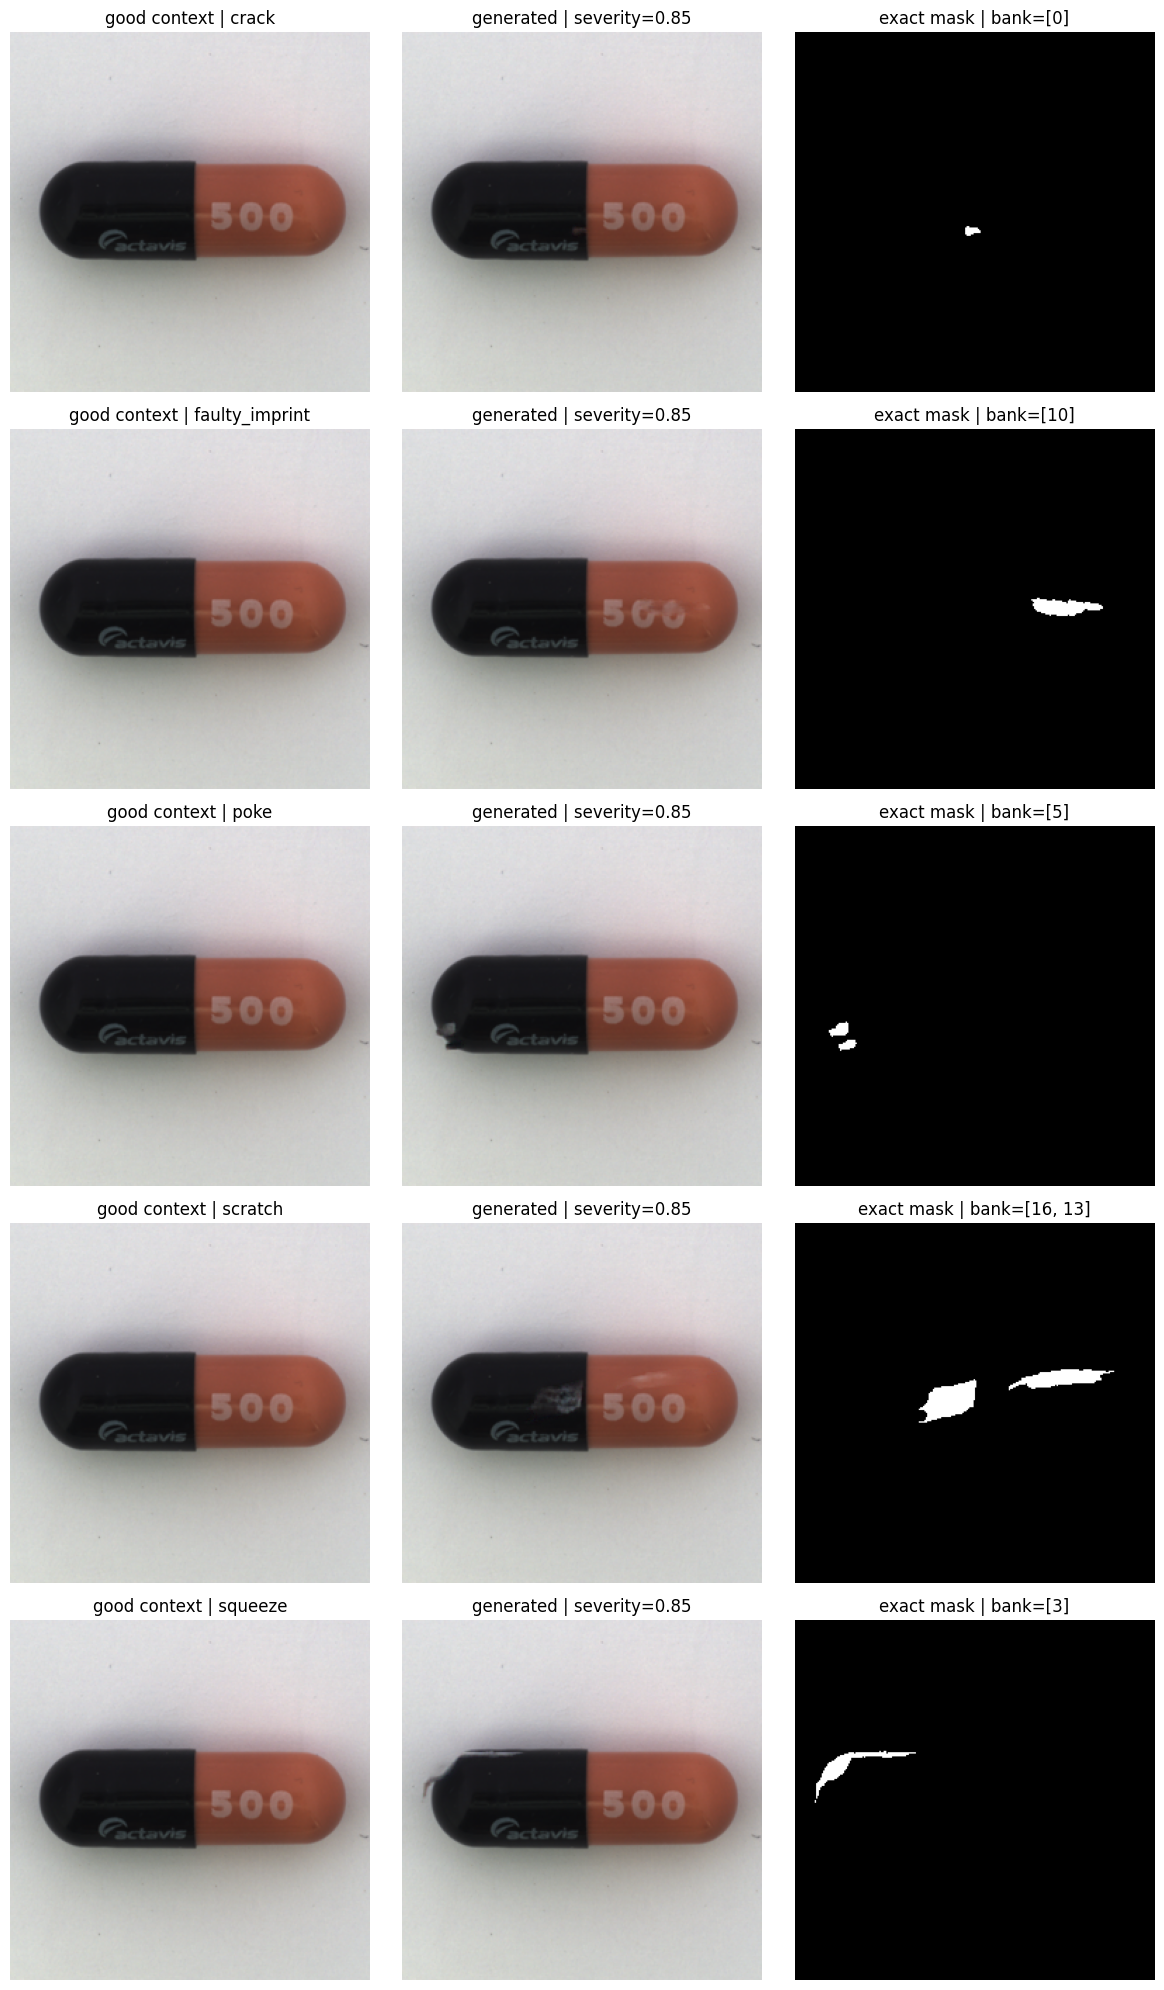

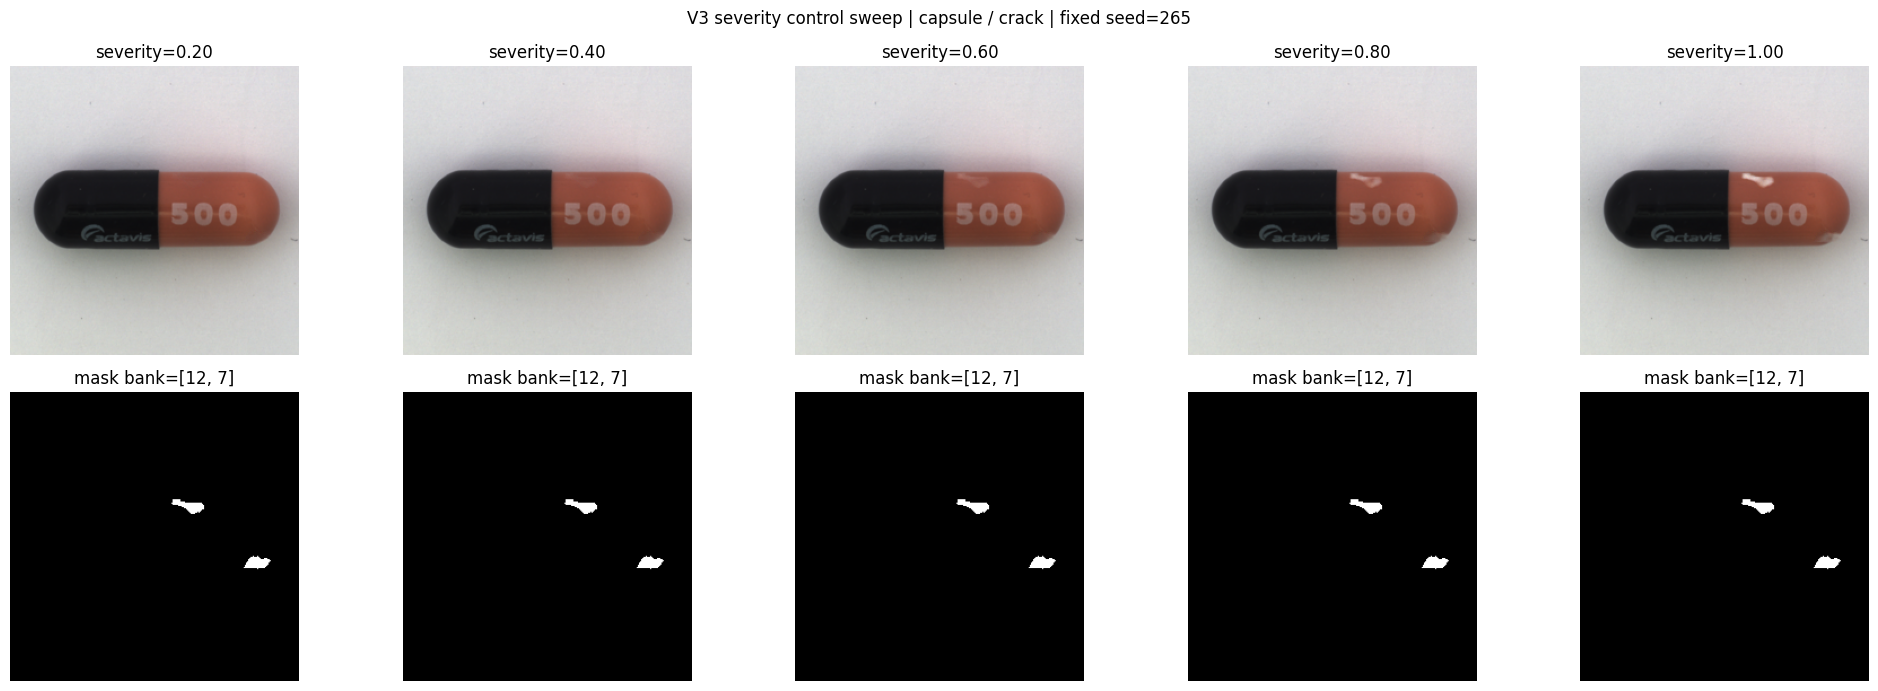

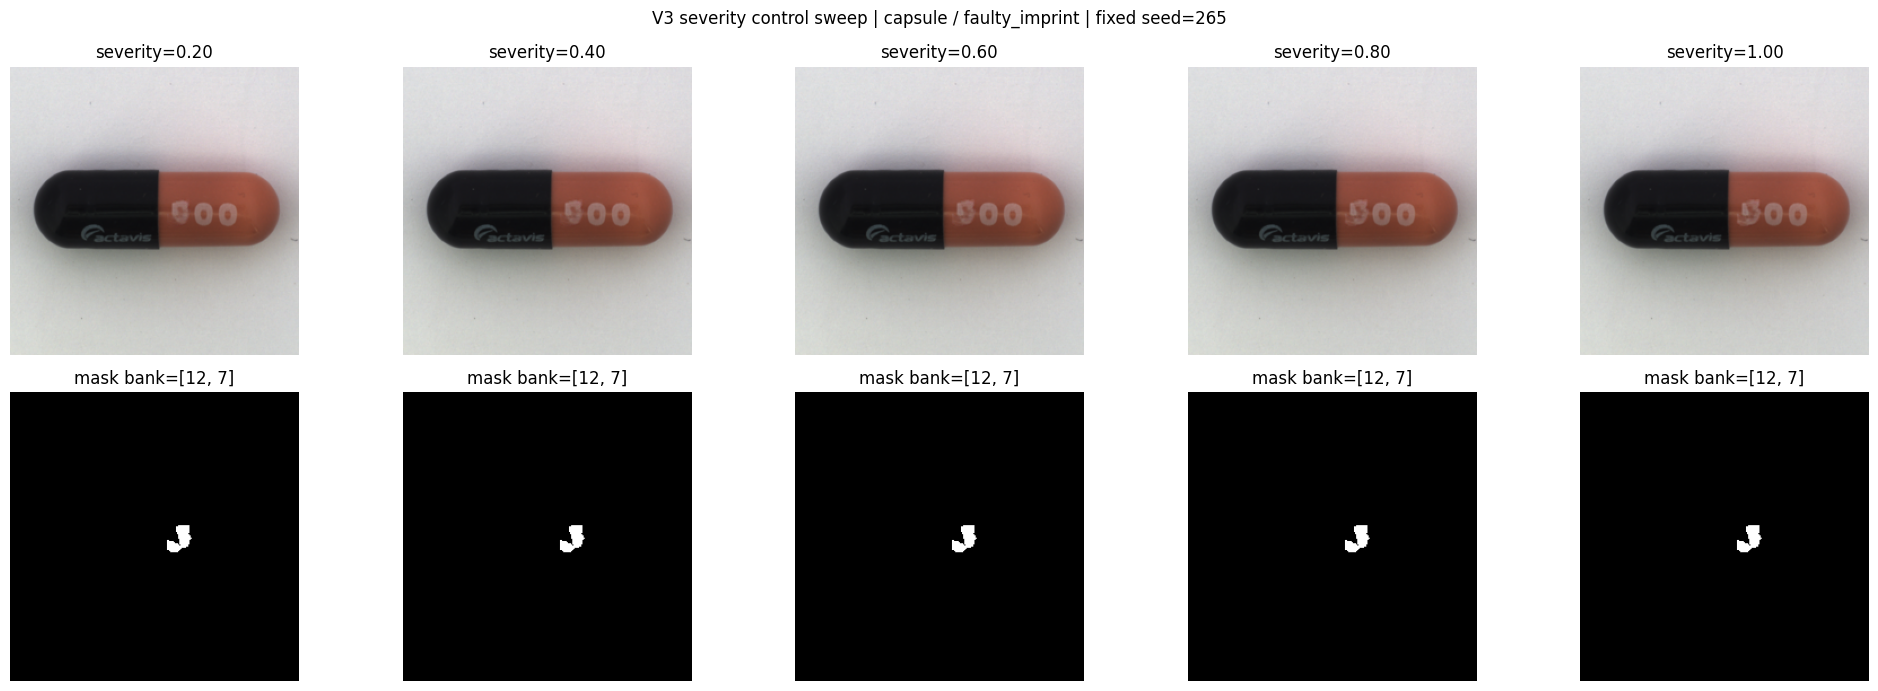

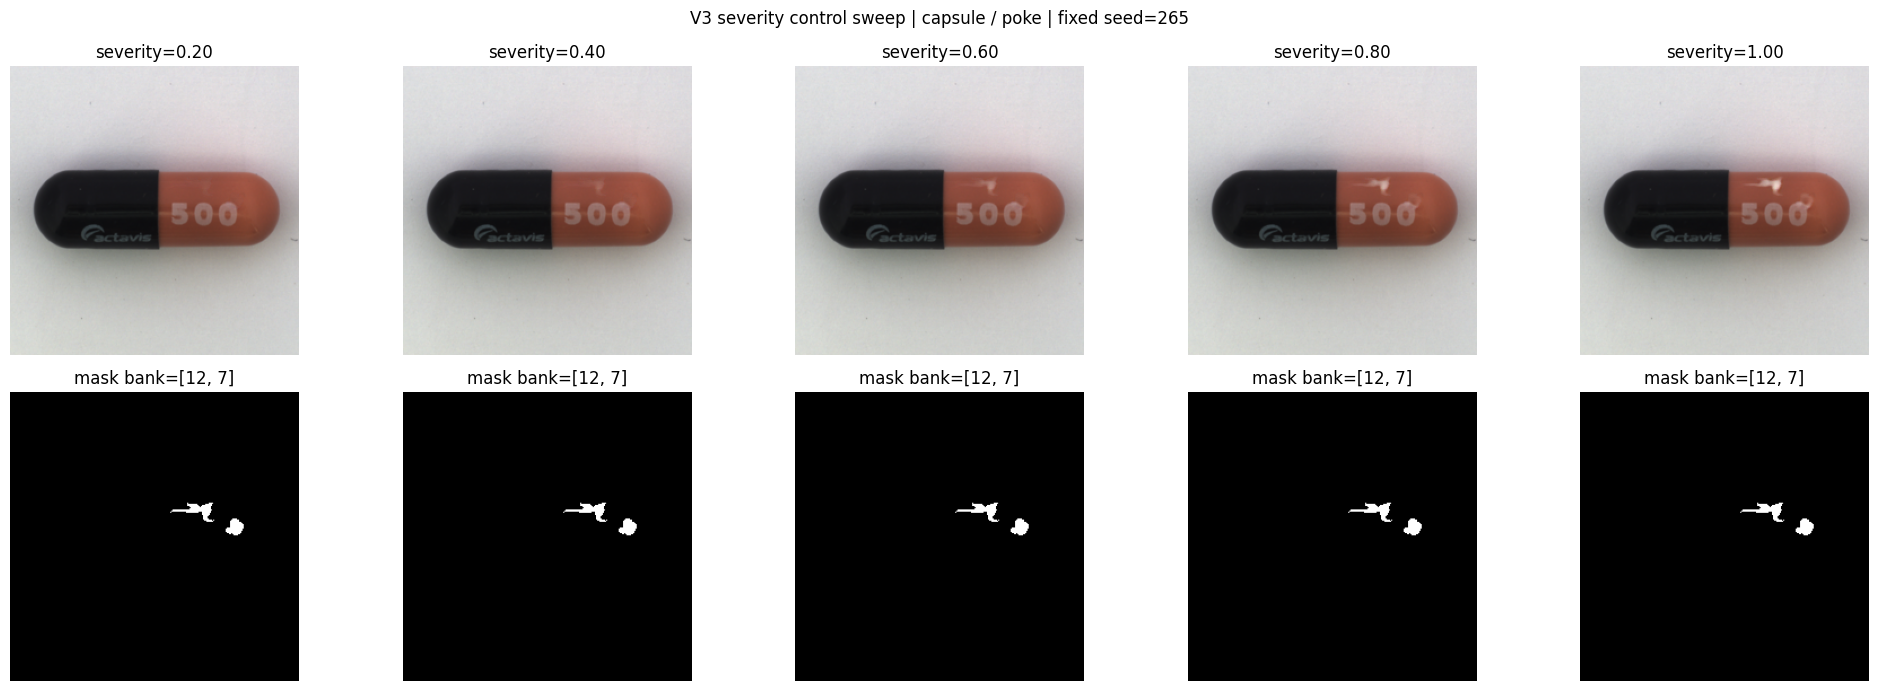

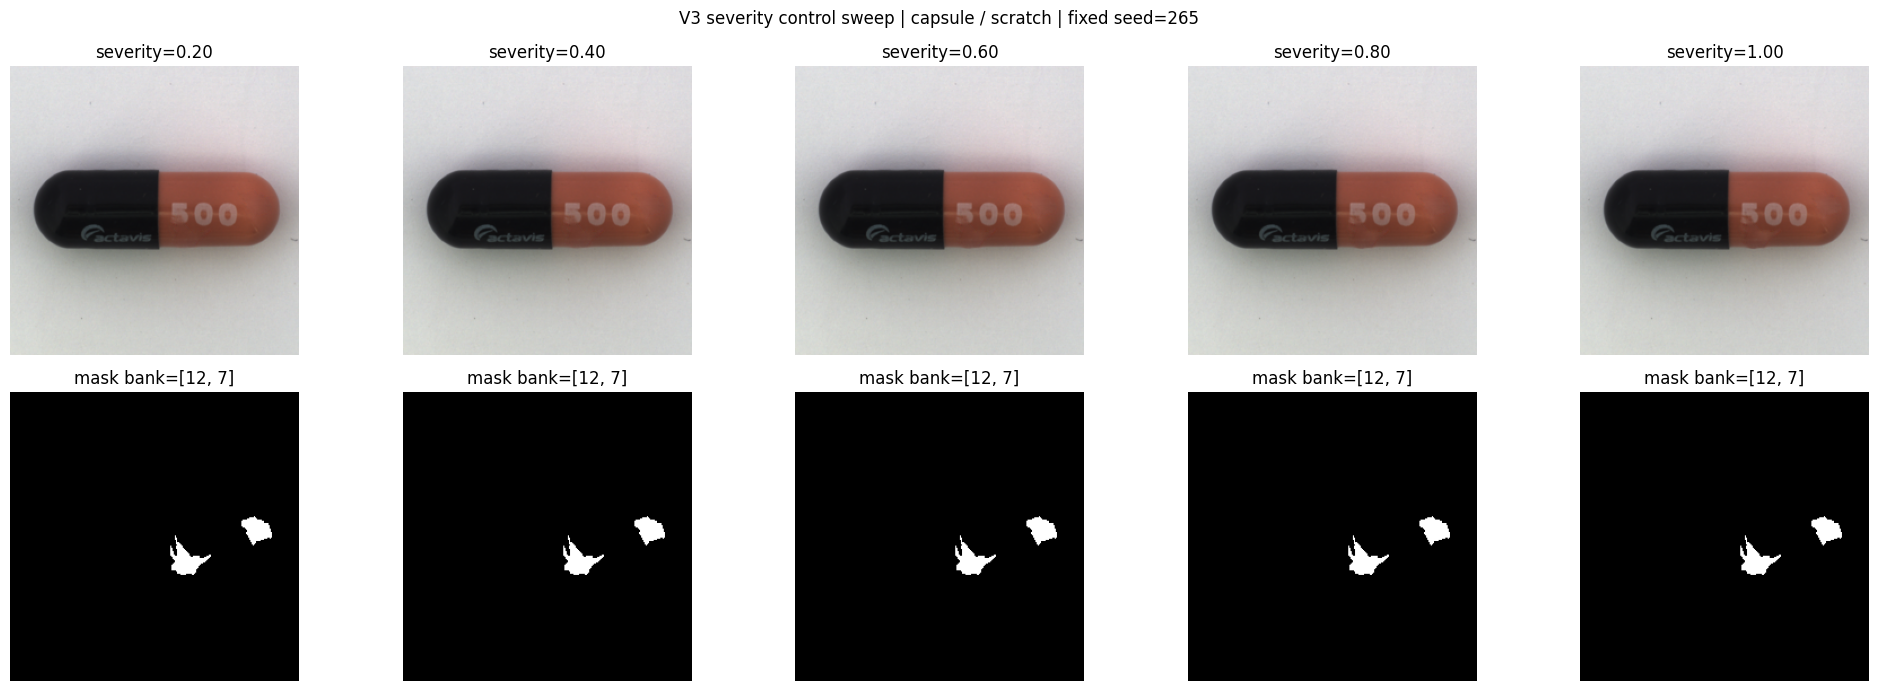

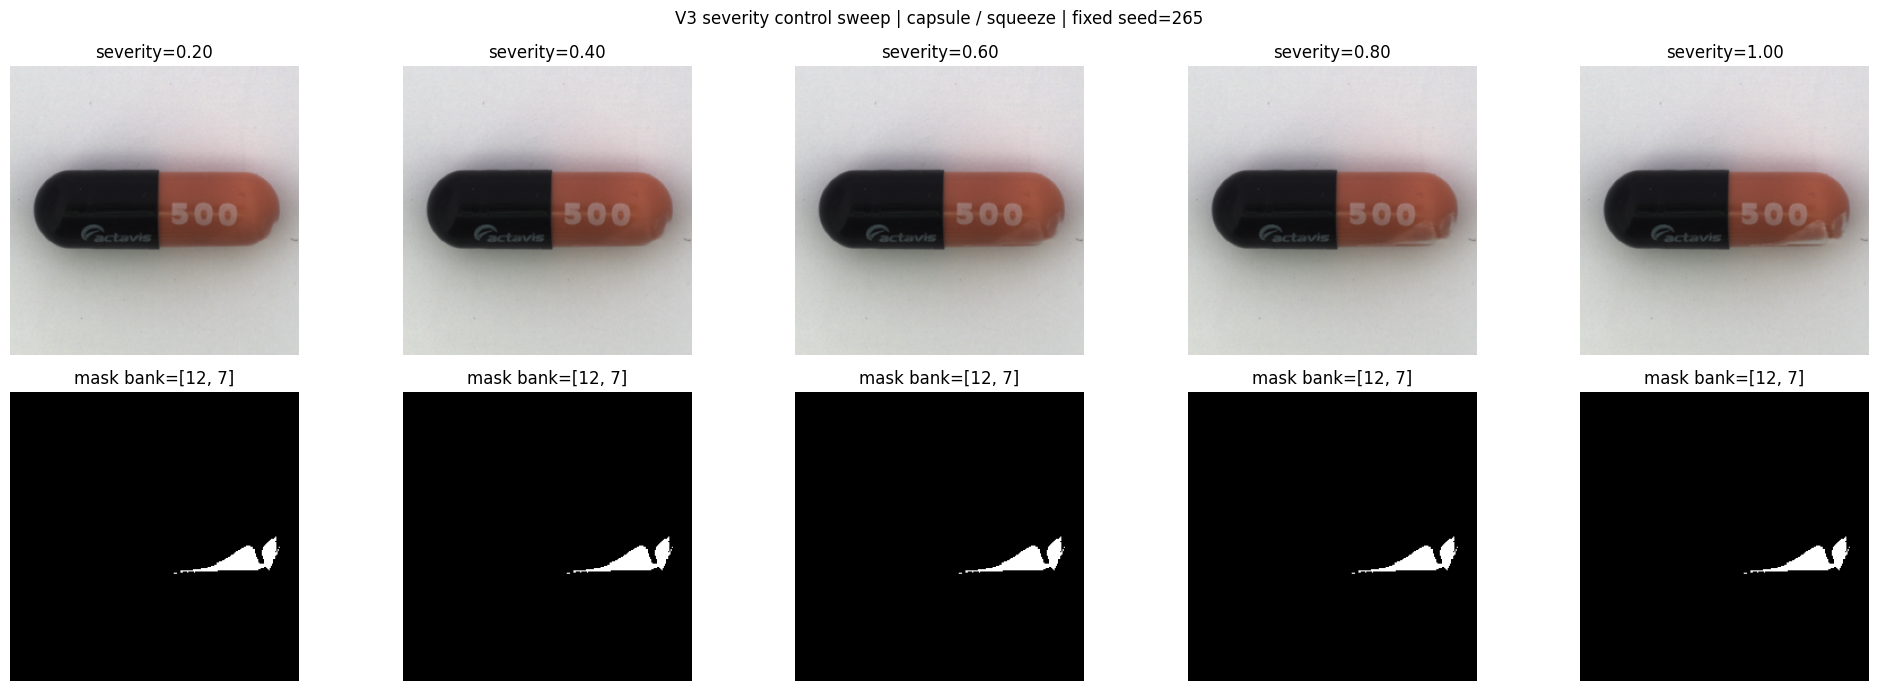

Severity sweep diagnostics:
{'severity': 0.2, 'seed': 265, 'defect_type': 'crack', 'source_indices': [12, 7], 'mean_masked_change': 0.030080745830363773, 'mean_outside_change': 2.1410150261392613e-05}
{'severity': 0.4, 'seed': 265, 'defect_type': 'crack', 'source_indices': [12, 7], 'mean_masked_change': 0.048426378358547136, 'mean_outside_change': 2.254998854631456e-05}
{'severity': 0.6, 'seed': 265, 'defect_type': 'crack', 'source_indices': [12, 7], 'mean_masked_change': 0.09866009141765811, 'mean_outside_change': 2.5455889013544082e-05}
{'severity': 0.8, 'seed': 265, 'defect_type': 'crack', 'source_indices': [12, 7], 'mean_masked_change': 0.21101127107937162, 'mean_outside_change': 2.6940276140404088e-05}
{'severity': 1.0, 'seed': 265, 'defect_type': 'crack', 'source_indices': [12, 7], 'mean_masked_change': 0.3715371408968893, 'mean_outside_change': 3.1768889468543454e-05}
{'severity': 0.2, 'seed': 265, 'defect_type': 'faulty_imprint', 'source_indices': [12, 7], 'mean_masked_change':

In [14]:
@torch.no_grad()
def generate_from_generalized_bank(adapter, mask_bank, context, defect_type,
                                   severity=0.85, steps=30, seed=123,
                                   scale=1.5):
    """No-reference inference with explicit severity control.

    The same seed fixes the selected generalized mask and appearance noise;
    changing only severity therefore gives a controlled severity sweep.
    """
    adapter.eval()
    base_model.eval()
    severity = float(np.clip(severity, 0.0, 1.0))
    if defect_type not in type_to_id:
        raise KeyError(f"Unknown type {defect_type}; choose from {type_names}")
    batch = context.shape[0]
    if batch != 1:
        raise ValueError("Use one context image per generated sample for deterministic bank seeds.")
    core_mask, source_indices = mask_bank.sample(
        defect_type,
        seed,
        inference=True,
        device=context.device,
        context=context,
    )
    core_mask = core_mask.unsqueeze(0).float()
    if int(core_mask.sum().item()) < MIN_MASK_PIXELS:
        raise RuntimeError("Generalized empirical mask bank produced an empty mask.")
    gate = soft_generation_mask(core_mask, radius=3)
    visible = context * (1 - core_mask)
    foreground = estimate_foreground(context)
    type_id = torch.tensor([type_to_id[defect_type]], device=context.device)
    severity_tensor = torch.tensor(
        [severity], device=context.device, dtype=torch.float32
    )
    severity_gain = severity_tensor.view(-1, 1, 1, 1) if SEVERITY_RESIDUAL_GAIN else 1.0
    generator = torch.Generator(device=context.device)
    generator.manual_seed(int(seed))
    known_noise = torch.randn(
        context.shape, device=context.device, dtype=context.dtype, generator=generator
    )
    sample = torch.randn(
        context.shape, device=context.device, dtype=context.dtype, generator=generator
    )
    appearance_z = torch.randn(
        batch, APPEARANCE_Z_DIM, IMAGE_SIZE, IMAGE_SIZE,
        device=context.device, dtype=context.dtype, generator=generator
    )
    sample_scheduler.set_timesteps(steps, device=context.device)
    first_t = sample_scheduler.timesteps[0]
    first_batch = torch.full(
        (batch,), int(first_t.item()), device=context.device, dtype=torch.long
    )
    known_at_first = sample_scheduler.add_noise(context, known_noise, first_batch)
    sample = sample * gate + known_at_first * (1 - gate)
    for step_index, timestep in enumerate(sample_scheduler.timesteps):
        timestep_batch = torch.full(
            (batch,), int(timestep.item()), device=context.device, dtype=torch.long
        )
        base_input = torch.cat([sample, core_mask, visible, foreground], dim=1)
        with amp_context():
            base_noise = base_model(base_input, timestep_batch)
            adapter_delta = adapter(
                sample, core_mask, gate, visible, foreground, appearance_z,
                timestep_batch, type_id, severity_tensor,
            )
            predicted_noise = base_noise + float(scale) * severity_gain * adapter_delta * gate
        previous = sample_scheduler.step(
            predicted_noise, timestep, sample, eta=0.0
        ).prev_sample
        if step_index + 1 < len(sample_scheduler.timesteps):
            next_t = sample_scheduler.timesteps[step_index + 1]
            next_batch = torch.full(
                (batch,), int(next_t.item()), device=context.device, dtype=torch.long
            )
            known_next = sample_scheduler.add_noise(context, known_noise, next_batch)
        else:
            known_next = context
        sample = previous * gate + known_next * (1 - gate)
    return sample.clamp(-1, 1), core_mask, source_indices


def mean_masked_change(generated, context, mask):
    region = mask.expand_as(generated)
    return float(((generated - context).abs() * region).sum().item() / (region.sum().item() + 1e-6))


def mean_outside_change(generated, context, gate):
    region = (1 - gate).expand_as(generated)
    return float(((generated - context).abs() * region).sum().item() / (region.sum().item() + 1e-6))

def save_generation_artifacts(generated, mask, *, defect_type, severity,
                              seed, source_indices, prefix):
    """Persist an image, the exact binary mask, and auditable metadata."""
    image_path = OUTPUT_DIR / f"{prefix}.png"
    mask_path = OUTPUT_DIR / f"{prefix}_mask.png"
    metadata_path = OUTPUT_DIR / f"{prefix}.json"
    save_tensor_image(generated[0], image_path)
    save_tensor_mask(mask[0], mask_path)
    metadata = {
        "category": CATEGORY,
        "defect_type": defect_type,
        "severity": float(severity),
        "seed": int(seed),
        "source_indices": [int(index) for index in source_indices],
        "source_mask_paths": [
            mask_bank.source_paths_by_type[defect_type][int(index)]
            for index in source_indices
        ],
        "image_path": str(image_path),
        "exact_mask_path": str(mask_path),
        "mask_sha256": __import__("hashlib").sha256(mask_path.read_bytes()).hexdigest(),
        "normal_checkpoint": str(NORMAL_CHECKPOINT),
        "mask_bank": str(MASK_BANK_PATH),
        "inference_steps": int(INFER_STEPS),
        "adapter_scale": float(ADAPTER_SCALE),
        "severity_residual_gain": bool(SEVERITY_RESIDUAL_GAIN),
        "no_anomaly_reference_at_inference": True,
    }
    metadata_path.write_text(json.dumps(metadata, indent=2))
    return metadata


# One deterministic smoke test per type using the generalized bank. Each
# sample gets an exact mask file plus a JSON record of seed/source/severity.
if RUN_DEMOS:
    good_image = load_image_tensor(normal_paths[0]).unsqueeze(0).to(DEVICE)
    demo_rows = []
    for type_index, smoke_type in enumerate(type_names):
        seed = 98745632 + type_index * 7919
        smoke_image, smoke_mask, smoke_sources = generate_from_generalized_bank(
            adapter, mask_bank, good_image, smoke_type,
            severity=0.85, steps=INFER_STEPS, seed=seed, scale=ADAPTER_SCALE,
        )
        metadata = save_generation_artifacts(
            smoke_image,
            smoke_mask,
            defect_type=smoke_type,
            severity=0.85,
            seed=seed,
            source_indices=smoke_sources,
            prefix=f"v3_smoke_{smoke_type}",
        )
        demo_rows.append((smoke_type, smoke_image[0].detach().cpu(), smoke_mask[0, 0].detach().cpu(), smoke_sources))
        print(
            f"demo {smoke_type}: source_indices={smoke_sources}, seed={seed}, "
            f"severity=0.85, mask_sha256={metadata['mask_sha256']}"
        )
    figure, axes = plt.subplots(len(demo_rows), 3, figsize=(12, 4 * len(demo_rows)), squeeze=False)
    for row, (name, image, mask, sources) in enumerate(demo_rows):
        axes[row, 0].imshow(tensor_to_display(good_image[0])); axes[row, 0].set_title(f"good context | {name}")
        axes[row, 1].imshow(tensor_to_display(image)); axes[row, 1].set_title(f"generated | severity=0.85")
        axes[row, 2].imshow(mask, cmap="gray"); axes[row, 2].set_title(f"exact mask | bank={sources}")
        for column in range(3): axes[row, column].axis("off")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / "v3_no_reference_generation_demos.png", dpi=160)
    plt.show(); plt.close(figure)

# Fixed-seed severity sweep: only severity changes, while bank source and z
# stay deterministic. The saved JSON records masked/outside changes and the
# exact shared mask. By default one type is swept for a practical run; set
SEVERITY_SWEEP_ALL_TYPES=True #for a per-type controlled diagnostic.
if RUN_SEVERITY_SWEEP:
    good_image = load_image_tensor(normal_paths[0]).unsqueeze(0).to(DEVICE)
    sweep_types = type_names if SEVERITY_SWEEP_ALL_TYPES else [type_names[0]]
    sweep_seed = 265
    severity_values = np.linspace(
        SEVERITY_LOW, SEVERITY_HIGH, 5
    ).round(3).tolist()
    all_sweep_rows = []
    for sweep_type in sweep_types:
        sweep_rows = []
        figure, axes = plt.subplots(2, len(severity_values), figsize=(20, 7))
        for column, severity in enumerate(severity_values):
            generated, mask, sources = generate_from_generalized_bank(
                adapter, mask_bank, good_image, sweep_type,
                severity=severity, steps=INFER_STEPS,
                seed=sweep_seed, scale=ADAPTER_SCALE,
            )
            axes[0, column].imshow(tensor_to_display(generated[0]))
            axes[0, column].set_title(f"severity={severity:.2f}")
            axes[1, column].imshow(mask[0, 0].cpu(), cmap="gray")
            axes[1, column].set_title(f"mask bank={sources}")
            for row in range(2): axes[row, column].axis("off")
            row = {
                "severity": severity,
                "seed": sweep_seed,
                "defect_type": sweep_type,
                "source_indices": sources,
                "mean_masked_change": mean_masked_change(generated, good_image, mask),
                "mean_outside_change": mean_outside_change(generated, good_image, soft_generation_mask(mask, radius=3)),
            }
            all_sweep_rows.append(row)
            sweep_rows.append(row)
            # Every severity receives an image artifact and JSON metadata; the
            # exact mask is repeated intentionally because the seed is fixed.
            save_generation_artifacts(
                generated,
                mask,
                defect_type=sweep_type,
                severity=severity,
                seed=sweep_seed,
                source_indices=sources,
                prefix=f"v3_sweep_{sweep_type}_severity_{severity:.2f}",
            )
        figure.suptitle(f"V3 severity control sweep | {CATEGORY} / {sweep_type} | fixed seed={sweep_seed}")
        figure.tight_layout()
        figure.savefig(OUTPUT_DIR / f"v3_severity_sweep_{sweep_type}.png", dpi=160)
        plt.show(); plt.close(figure)
        (OUTPUT_DIR / f"v3_severity_sweep_{sweep_type}.json").write_text(
            json.dumps(sweep_rows, indent=2)
        )
    (OUTPUT_DIR / "v3_severity_sweep_all.json").write_text(
        json.dumps(all_sweep_rows, indent=2)
    )
    print("Severity sweep diagnostics:")
    for row in all_sweep_rows:
        print(row)


## Outputs and interpretation

The V3 adapter checkpoint and generalized mask-bank checkpoint are category-specific. The empirical bank remains training-only; validation masks are used only for coverage diagnostics. The severity sweep is a controlled qualitative/diagnostic experiment, not a downstream detector metric. Compare the per-type `v3_severity_sweep_<type>.json` files for monotonic masked change and low outside-context change before exposing the slider in the separate UI.

Each generated sample writes an image, an exact binary mask, and a JSON record containing category, type, continuous severity, seed, source bank indices/paths, mask SHA-256, and inference settings. Do not claim improved realism, mask IoU, ROC-AUC, AP, Dice, or detector performance until those measurements are run on held-out data.